# 03 — Tratamento e Limpeza do `varejo.csv`

### Projeto Varejo · Fase 2 do roadmap · Execução do *Roteiro Completo de Limpeza* (10 fases)

| Campo | Valor |
|---|---|
| **Notebook** | `notebooks/03-diagnostico.ipynb` |
| **Roteiro de referência** | *Roteiro Completo de Limpeza de Dataset — Todas as Fórmulas* (10 fases, numeração preservada) |
| **Entrada** | `data/raw/varejo.csv` — somente leitura, nunca alterado |
| **SHA-256 esperado** | `446a6b0baefb04d93532ffbe5f86098cde09d68af1db152c8f4ba61c783796c7` |
| **Saídas** | `data/processed/varejo_limpo.csv` · `.xlsx` · `.parquet` · `data/interim/varejo_original_backup.csv` · `docs/log_limpeza.txt` |
| **Elaboração** | Claude (Anthropic), atuando como analista de dados sênior, a pedido do autor do projeto |
| **Versão** | 1.0 — outubro de 2026 |
| **Compatibilidade** | Windows 10 e Ubuntu · pandas 2.x e 3.x · Python 3.11+ |
| **Tempo de execução** | menos de 30 segundos |

---

## Natureza do dado

O `varejo.csv` é um **conjunto fictício**, gerado para estudo. Os defeitos que ele contém foram
inseridos de propósito e são reais enquanto exercício técnico. Nenhuma conclusão deste notebook
descreve uma operação de varejo existente. O objetivo é demonstrar **método**.

## Como este notebook foi construído

O roteiro do autor define 10 fases e mais de 40 sub-passos com fórmulas prontas. Este notebook
**preserva a numeração de cada sub-passo** — `[2.1.4]`, `[4.3.4]` etc. — para que qualquer leitor
consiga ir do roteiro ao código e do código ao roteiro sem esforço.

Antes de escrever uma linha, cada fórmula foi executada contra este arquivo específico e seu efeito
foi medido. A maioria funciona como está. Algumas, corretas em tese, **danificam este dataset em
particular**. Nesses casos a fórmula original é mantida no texto, seu efeito é **demonstrado numa
cópia descartável**, e a alternativa adotada é aplicada e justificada.

Um roteiro genérico é escrito antes de se conhecer o dado. A responsabilidade do analista é
executá-lo **sabendo** o que cada passo faz com o dado que está na mesa.

### Legenda de status de cada sub-passo

| Marca | Significado |
|:---:|---|
| ✅ | **Executado** exatamente como no roteiro |
| ⚙️ | **Executado com ajuste** — mesma intenção, implementação corrigida para este dado |
| ⛔ | **Não aplicado** — o efeito é demonstrado numa cópia e a alternativa é registrada |
| ➕ | **Acrescentado** pelo analista — passo ausente do roteiro, necessário para este dado |

Cada passo, além de executar, **registra no log** quantas linhas e células alterou. O log vira
`docs/log_limpeza.txt` na Fase 10.

In [2]:
print('Pontos a ver e tomar decisão')
print('[2.1.4] Preencher nulos com a média')

Pontos a ver e tomar decisão
[2.1.4] Preencher nulos com a média


## Sumário executivo

*Valores apurados na execução de referência. Reexecutar o notebook atualiza as saídas das células,
não este texto.*

**O que o arquivo bruto tem de errado**

- **998 células ausentes**, das quais 279 escritas como marcadores textuais
  (`--`, `?`, `-`, `sem informacao`, `N/A`, `null`). A leitura padrão do pandas reconhece parte
  deles e deixa **149 passarem como texto válido**.
- **87 datas** em `DD/MM/AAAA` misturadas a 913 em `AAAA-MM-DD`.
- **Mesmos valores escritos de várias formas**: 31 grafias para 7 categorias, 18 para 4 canais,
  32 para 15 UFs e 286 para 245 clientes — variações de espaço e de maiúsculas.
- **7 registros com vírgula decimal deslocada** duas casas — o mais visível registra
  R$ 9.468,00 onde a conta correta dá R$ 94,68.

**Os quatro achados mais graves desta execução**

1. **A conversão de datas do roteiro (`[3.1.2]`) depende da versão do pandas.** No pandas 2.2 ela
   acerta; no pandas 3.0 ela **inverte dia e mês em 297 datas**, sem erro nem aviso.
2. **Remover dígitos do cliente (`[4.3.4]`) colapsaria 245 clientes em um só**, porque todos os
   códigos têm o formato `CLI-NNNN`.
3. **Preencher preço pela média (`[2.1.4]`)** quebraria a identidade de valor em centenas de
   linhas e quadruplicaria o preço de Hortifrúti. O preço é **reconstruído** pela própria venda.
4. **Preencher canal e UF pela moda (`[2.4.4]`, `[2.5.4]`)** faria a Loja saltar de 44% para 57%
   das vendas e SP de 30% para 47%, sem nenhuma evidência. A ausência é **rotulada**, não disfarçada.

E um achado de impacto direto nos números: os 7 registros com vírgula deslocada **inflavam o
faturamento em 21,9%** — R$ 133.320,19 no bruto contra R$ 109.344,37 na base limpa.

**Resultado:** 1.000 linhas preservadas, nenhuma removida, zero nulos, zero duplicatas, e a
identidade `valor_total = quantidade × preco_unit × (1 − desconto_pct/100)` válida em 100% da base.
Cada valor reconstruído ou corrigido é rastreável por três colunas de origem.

## Como executar

**Windows 10 — Anaconda Prompt**
```bat
conda activate varejo
cd /d C:\Git\Projeto-Varejo
jupyter lab
```

**Ubuntu — terminal**
```bash
conda activate varejo
cd ~/Git/Projeto-Varejo
jupyter lab
```

Abra `notebooks/03-diagnostico.ipynb`, confira que o núcleo é **Python (varejo)** e execute
*Run → Run All Cells*. O notebook funciona aberto tanto da raiz quanto de dentro de `notebooks/`.

**Bibliotecas necessárias:** `pandas`, `numpy`, `matplotlib`. Para salvar em Excel, `openpyxl`;
para Parquet, `pyarrow`. Ausentes, a Fase 10 avisa e segue com os demais formatos.

---
# FASE 0 — Preparação do ambiente ➕

O roteiro começa direto no diagnóstico. Antes dele, três providências que um projeto
reproduzível exige: caminhos independentes do sistema operacional, verificação de que o arquivo
é o esperado, e um mecanismo de log que registre cada passo **no momento em que acontece**.

In [6]:
from pathlib import Path
from datetime import datetime
import hashlib
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print(f"Sistema    : {platform.system()} {platform.release()}")
print(f"Python     : {sys.version.split()[0]}")
print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"matplotlib : {matplotlib.__version__}")

Sistema    : Windows 10
Python     : 3.12.7
pandas     : 2.2.2
numpy      : 1.26.4
matplotlib : 3.9.2


### Caminhos

O `pathlib` monta o separador certo para cada sistema: barra invertida no Windows, barra normal
no Ubuntu. A âncora abaixo faz o notebook funcionar aberto da raiz ou de dentro de `notebooks/`.

In [8]:
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

BRUTO      = RAIZ / "data" / "raw" / "varejo.csv"
INTERIM    = RAIZ / "data" / "interim"
PROCESSADO = RAIZ / "data" / "processed"
DOCS       = RAIZ / "docs"
for pasta in (INTERIM, PROCESSADO, DOCS):
    pasta.mkdir(parents=True, exist_ok=True)

print(f"Raiz do projeto : {RAIZ}")
print(f"Arquivo bruto   : {BRUTO}")
print(f"Existe          : {BRUTO.exists()}")

Raiz do projeto : C:\Git\Projeto-Varejo
Arquivo bruto   : C:\Git\Projeto-Varejo\data\raw\varejo.csv
Existe          : True


### Integridade do arquivo de entrada

Se o hash não bater, o arquivo foi alterado — quase sempre por ter sido aberto e **salvo** no
Excel, que reescreve o CSV. Nesse caso, pare e recoloque o original em `data/raw/`.

In [10]:
SHA256_ESPERADO = "446a6b0baefb04d93532ffbe5f86098cde09d68af1db152c8f4ba61c783796c7"
sha256 = hashlib.sha256(BRUTO.read_bytes()).hexdigest()

print(f"SHA-256 obtido  : {sha256}")
print(f"SHA-256 esperado: {SHA256_ESPERADO}")
if sha256 == SHA256_ESPERADO:
    print("✅ Arquivo íntegro. Os números deste notebook valem para ele.")
else:
    print("❌ ATENÇÃO: o arquivo difere do original. Os números documentados não se aplicam.")

SHA-256 obtido  : 446a6b0baefb04d93532ffbe5f86098cde09d68af1db152c8f4ba61c783796c7
SHA-256 esperado: 446a6b0baefb04d93532ffbe5f86098cde09d68af1db152c8f4ba61c783796c7
✅ Arquivo íntegro. Os números deste notebook valem para ele.


### Registro de passos (log)

Cada sub-passo chama `registrar()`. O log nasce durante a execução, não da memória depois dela
— é a diferença entre documentação e reconstrução.

In [12]:
LOG = []

def registrar(passo, descricao, status, afetados=0, nota=""):
    '''Registra um sub-passo do roteiro no log de limpeza.

    Parameters
    ----------
    passo : str
        Numeração do roteiro, ex. "2.1.4". Passos acrescentados usam sufixo, ex. "2.0.3".
    descricao : str
        O que o passo faz, em uma linha.
    status : str
        "✅" executado como no roteiro, "⚙️" com ajuste, "⛔" não aplicado, "➕" acrescentado.
    afetados : int
        Linhas removidas ou células alteradas pelo passo. Zero é informação, não omissão.
    nota : str
        Justificativa ou detalhe relevante.
    '''
    LOG.append({
        "passo": passo, "status": status, "descricao": descricao,
        "afetados": int(afetados), "linhas_apos": len(df) if "df" in globals() else None,
        "nota": nota,
    })
    print(f"{status} [{passo}] {descricao} — afetados: {afetados}" + (f" · {nota}" if nota else ""))

### Constantes do tratamento

Todas as decisões parametrizáveis ficam aqui, num único lugar. Alterar uma regra é editar esta
célula, não procurar em vinte células espalhadas.

In [14]:
# Formas como a AUSÊNCIA aparece escrita neste arquivo (levantadas no 01-diagnostico)
SENTINELAS = {"--", "?", "-", "sem informacao", "N/A", "NA", "n/a", "null", "NULL", ""}

# Rótulos de ausência explícita para colunas categóricas (ver [2.4.4] e [2.5.4])
ROTULO_CANAL = "Não informado"
ROTULO_UF    = "NI"            # mantém o esquema de 2 caracteres da coluna

# Tolerância da identidade de valor, em reais (roteiro [5.4.7])
TOLERANCIA = 0.01

# Dias da semana em português, independentes do idioma do sistema operacional
DIAS_PT = {0: "Segunda-feira", 1: "Terça-feira", 2: "Quarta-feira", 3: "Quinta-feira",
           4: "Sexta-feira", 5: "Sábado", 6: "Domingo"}

NUMERICAS = ["quantidade", "preco_unit", "desconto_pct", "valor_total"]
TEXTO     = ["cliente", "categoria", "canal", "uf"]

### Cópia fiel do original — aviso crítico nº 3 do roteiro

O roteiro pede `df_original = df.copy()` antes de começar. Aqui a cópia é feita com **leitura
controlada**: tudo como texto (`dtype=str`) e sem conversão automática de nulos
(`keep_default_na=False`). Assim `df_original` guarda **exatamente** o que está escrito no arquivo,
caractere por caractere — inclusive os espaços sobrando e os marcadores de ausência.

In [16]:
df_original = pd.read_csv(BRUTO, dtype=str, keep_default_na=False, encoding="utf-8")
LINHAS_ORIGINAL = len(df_original)
print(f"df_original: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas (tudo como texto)")
df_original.head()

df_original: 1000 linhas × 10 colunas (tudo como texto)


,id_venda,data,cliente,categoria,canal,uf,quantidade,preco_unit,desconto_pct,valor_total
0,1,2024-08-08,CLI-0069,Limpeza,,BA,1,,0.45,50.63
1,2,2024-11-12,CLI-0050,Limpeza,Loja,RJ,4,111.06,4.91,422.43
2,3,2024-09-08,CLI-0149,Padaria,Loja,,5,10.73,4.86,5104.00
3,4,2024-04-07,CLI-0044,Bebidas,,SP,2,87.89,2.87,170.74
4,5,2024-06-27,CLI-0140,Hortifruti,Loja,SP,1,8.10,,8.07


---
# FASE 1 — Diagnóstico inicial

> **Regra da fase:** apenas observação. Nenhuma modificação.

As fórmulas desta fase são executadas **literalmente**, sobre uma leitura padrão do pandas
(`pd.read_csv` sem parâmetros), porque é assim que o roteiro as escreve. Ao final, o passo `[1.4]`
mostra o que essa leitura padrão **não consegue ver** — e por que isso muda a Fase 2.

In [18]:
df = pd.read_csv(BRUTO)   # leitura padrão, como pressuposto pelo roteiro
print("Leitura padrão concluída.")

Leitura padrão concluída.


## [1.1] Avaliação geral do dataset

### [1.1.1] Dimensões ✅
```python
df.shape
```

In [20]:
print(df.shape)
registrar("1.1.1", "dimensões verificadas", "✅", 0, f"{df.shape[0]} linhas × {df.shape[1]} colunas")

(1000, 10)
✅ [1.1.1] dimensões verificadas — afetados: 0 · 1000 linhas × 10 colunas


### [1.1.2] Tipos de dados ✅
```python
df.dtypes
```
**Leitura sênior.** Observe `preco_unit` e `desconto_pct`: são colunas de **números** e vieram
como **texto**. Uma única célula com `--` basta para o pandas desistir da coluna inteira. Esse
é o primeiro sintoma de que existem ausências disfarçadas.

In [22]:
print(df.dtypes)
texto_indevido = [c for c in ["preco_unit", "desconto_pct"] if not pd.api.types.is_numeric_dtype(df[c])]
registrar("1.1.2", "tipos verificados", "✅", 0,
          f"colunas numéricas lidas como texto: {texto_indevido}")

id_venda          int64
data             object
cliente          object
categoria        object
canal            object
uf               object
quantidade        int64
preco_unit       object
desconto_pct     object
valor_total     float64
dtype: object
✅ [1.1.2] tipos verificados — afetados: 0 · colunas numéricas lidas como texto: ['preco_unit', 'desconto_pct']


### [1.1.3] Memória usada ✅
```python
df.memory_usage(deep=True)
```

In [24]:
mem = df.memory_usage(deep=True)
print(mem)
print(f"\nTotal: {mem.sum() / 1024:.1f} KB")
registrar("1.1.3", "memória verificada", "✅", 0, f"{mem.sum() / 1024:.1f} KB")

Index             132
id_venda         8000
data            59000
cliente         57063
categoria       56595
canal           48915
uf              47142
quantidade       8000
preco_unit      48902
desconto_pct    48474
valor_total      8000
dtype: int64

Total: 381.1 KB
✅ [1.1.3] memória verificada — afetados: 0 · 381.1 KB


## [1.2] Identificação de dados nulos

### [1.2.1] Nulos por coluna ✅
```python
df.isnull().sum()
```

In [26]:
nulos_leitura_padrao = df.isnull().sum()
print(nulos_leitura_padrao)
registrar("1.2.1", "nulos contados (leitura padrão)", "✅", 0,
          f"total aparente: {int(nulos_leitura_padrao.sum())}")

id_venda          0
data              0
cliente           0
categoria         0
canal           200
uf              208
quantidade        0
preco_unit      224
desconto_pct    217
valor_total       0
dtype: int64
✅ [1.2.1] nulos contados (leitura padrão) — afetados: 0 · total aparente: 849


### [1.2.2] Percentual de nulos ✅
```python
(df.isnull().sum() / len(df)) * 100
```

In [28]:
print(((df.isnull().sum() / len(df)) * 100).round(1))
registrar("1.2.2", "percentual de nulos calculado", "✅")

id_venda         0.0
data             0.0
cliente          0.0
categoria        0.0
canal           20.0
uf              20.8
quantidade       0.0
preco_unit      22.4
desconto_pct    21.7
valor_total      0.0
dtype: float64
✅ [1.2.2] percentual de nulos calculado — afetados: 0


### [1.2.3] Colunas com mais de 50% de nulos ✅
```python
df.columns[df.isnull().sum() > len(df) * 0.5].tolist()
```
**Leitura sênior.** Coluna com mais da metade vazia raramente se salva por imputação. Aqui a
lista sai vazia — nenhuma coluna está perdida.

In [30]:
acima_50 = df.columns[df.isnull().sum() > len(df) * 0.5].tolist()
print(acima_50)
registrar("1.2.3", "colunas com mais de 50% de nulos", "✅", len(acima_50), str(acima_50))

[]
✅ [1.2.3] colunas com mais de 50% de nulos — afetados: 0 · []


### [1.2.4] Padrão de nulos ⚙️
```python
df.isnull()
```
**Ajuste.** A fórmula devolve uma tabela de 1.000 × 10 valores `True`/`False`, que ninguém
consegue ler. A mesma informação vira um mapa visual: cada traço escuro é uma célula nula.

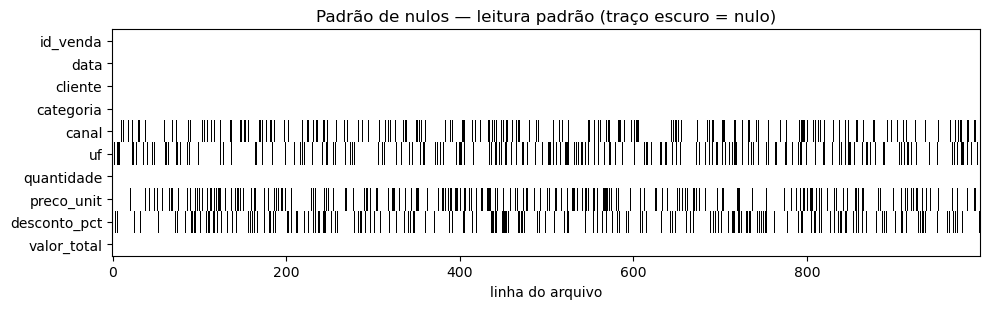

⚙️ [1.2.4] padrão de nulos visualizado — afetados: 0 · tabela booleana substituída por mapa visual


In [32]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(df.isnull().T.values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(df.columns)))
ax.set_yticklabels(df.columns)
ax.set_xlabel("linha do arquivo")
ax.set_title("Padrão de nulos — leitura padrão (traço escuro = nulo)")
plt.tight_layout()
plt.show()
registrar("1.2.4", "padrão de nulos visualizado", "⚙️", 0, "tabela booleana substituída por mapa visual")

**Leitura sênior do mapa.** Os nulos se espalham sem padrão por quatro colunas — `canal`, `uf`,
`preco_unit`, `desconto_pct` — e nunca atingem `id_venda`, `data`, `cliente` ou `valor_total`.
Ausência dispersa e sem padrão, em colunas não críticas, é o cenário mais favorável para
tratamento: não há indício de que um bloco inteiro de registros esteja corrompido.

## [1.3] Análise inicial de qualidade

### [1.3.1] Duplicatas completas ✅
```python
df.duplicated().sum()
```

In [35]:
dup_completas = int(df.duplicated().sum())
print(dup_completas)
registrar("1.3.1", "duplicatas completas", "✅", dup_completas)

0
✅ [1.3.1] duplicatas completas — afetados: 0


### [1.3.2] Duplicatas por ID ✅
```python
df['id_venda'].duplicated().sum()
```

In [37]:
dup_id = int(df["id_venda"].duplicated().sum())
print(dup_id)
registrar("1.3.2", "duplicatas por id_venda", "✅", dup_id)

0
✅ [1.3.2] duplicatas por id_venda — afetados: 0


### [1.3.3] Resumo estatístico ✅
```python
df.describe()
```
**Leitura sênior.** O resumo traz apenas três colunas — `id_venda`, `quantidade` e
`valor_total`. Preço e desconto **sumiram** do resumo porque estão como texto. E o máximo de
`valor_total` (R$ 9.468,00) contra um terceiro quartil de poucas dezenas de reais é o primeiro
sinal dos valores com vírgula deslocada.

In [39]:
display(df.describe().round(2))
registrar("1.3.3", "resumo estatístico", "✅", 0,
          f"colunas resumidas: {list(df.describe().columns)}")

,id_venda,quantidade,valor_total
count,1000.00,1000.00,1000.00
mean,500.50,2.65,133.32
std,288.82,2.04,412.99
min,1.00,1.00,1.48
25%,250.75,1.00,12.84
50%,500.50,2.00,42.34
75%,750.25,3.00,136.56
max,1000.00,12.00,9468.00


✅ [1.3.3] resumo estatístico — afetados: 0 · colunas resumidas: ['id_venda', 'quantidade', 'valor_total']


### [1.3.4] Informações gerais ✅
```python
df.info()
```

In [41]:
df.info()
registrar("1.3.4", "informações gerais", "✅")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_venda      1000 non-null   int64  
 1   data          1000 non-null   object 
 2   cliente       1000 non-null   object 
 3   categoria     1000 non-null   object 
 4   canal         800 non-null    object 
 5   uf            792 non-null    object 
 6   quantidade    1000 non-null   int64  
 7   preco_unit    776 non-null    object 
 8   desconto_pct  783 non-null    object 
 9   valor_total   1000 non-null   float64
dtypes: float64(1), int64(2), object(7)
memory usage: 78.3+ KB
✅ [1.3.4] informações gerais — afetados: 0


## [1.4] Ausências ocultas e inconsistências invisíveis à leitura padrão ➕

**Por que este passo existe.** As fórmulas `[1.2.x]` contam o que o pandas reconheceu como nulo.
Mas a leitura padrão só reconhece algumas grafias (`N/A`, `NULL`...). Quem digitou `--`, `?`,
`-` ou `sem informacao` criou uma ausência que o pandas trata como **texto válido**.

Comparar a leitura padrão com a leitura controlada mostra o tamanho do ponto cego.

In [43]:
linhas = []
for col in df_original.columns:
    s = df_original[col].str.strip()
    vazias = int((s == "").sum())
    marcadas = int(s.isin(SENTINELAS - {""}).sum())
    linhas.append({
        "coluna": col,
        "nulos_leitura_padrão": int(df[col].isnull().sum()),
        "vazias_reais": vazias,
        "marcadores_textuais": marcadas,
        "ausência_real": vazias + marcadas,
        "formas_encontradas": ", ".join(sorted(set(s[s.isin(SENTINELAS - {""})]))) or "—",
    })
ausencias = pd.DataFrame(linhas).set_index("coluna")
display(ausencias[ausencias["ausência_real"] > 0])

oculto = int(ausencias["ausência_real"].sum() - ausencias["nulos_leitura_padrão"].sum())
print(f"Ausência real total      : {int(ausencias['ausência_real'].sum())}")
print(f"Vista pela leitura padrão: {int(ausencias['nulos_leitura_padrão'].sum())}")
print(f"Ponto cego               : {oculto} células")
registrar("1.4", "ausências ocultas identificadas", "➕", oculto,
          "marcadores que a leitura padrão trata como texto")

,nulos_leitura_padrão,vazias_reais,marcadores_textuais,ausência_real,formas_encontradas
coluna,,,,,
canal,200,176,57,233,"-, --, ?, N/A, NULL, null, sem informacao"
uf,208,174,69,243,"-, --, ?, N/A, NULL, n/a, null, sem informacao"
preco_unit,224,190,70,260,"-, --, ?, N/A, NULL, null, sem informacao"
desconto_pct,217,179,83,262,"-, --, ?, N/A, NULL, null, sem informacao"


Ausência real total      : 998
Vista pela leitura padrão: 849
Ponto cego               : 149 células
➕ [1.4] ausências ocultas identificadas — afetados: 149 · marcadores que a leitura padrão trata como texto


**Outras inconsistências que só aparecem olhando os valores escritos:**

In [45]:
fmt = df_original["data"].str.strip().map(
    lambda v: "AAAA-MM-DD" if re.fullmatch(r"\d{4}-\d{2}-\d{2}", v)
    else "DD/MM/AAAA" if re.fullmatch(r"\d{2}/\d{2}/\d{4}", v) else "outro")
print("Formatos de data:", fmt.value_counts().to_dict())
print()
for col in TEXTO:
    s = df_original[col]
    validos = s[~s.str.strip().isin(SENTINELAS)]
    print(f"{col:<10} como escritas: {validos.nunique():>3}   "
          f"sem espaços: {validos.str.strip().nunique():>3}   "
          f"valores reais: {validos.str.strip().str.upper().nunique():>3}")
registrar("1.4", "formatos de data e grafias inventariados", "➕", 0,
          f"datas: {fmt.value_counts().to_dict()}")

Formatos de data: {'AAAA-MM-DD': 913, 'DD/MM/AAAA': 87}

cliente    como escritas: 286   sem espaços: 254   valores reais: 245
categoria  como escritas:  31   sem espaços:  17   valores reais:   7
canal      como escritas:  18   sem espaços:  10   valores reais:   4
uf         como escritas:  32   sem espaços:  22   valores reais:  15
➕ [1.4] formatos de data e grafias inventariados — afetados: 0 · datas: {'AAAA-MM-DD': 913, 'DD/MM/AAAA': 87}


**Fecho da Fase 1.** O diagnóstico confirma o que o `01-diagnostico` já havia levantado e
acrescenta uma consequência prática: **o tratamento não pode partir da leitura padrão**. Ele parte
da leitura controlada (`df_original`), onde cada ausência é visível e convertida de forma
deliberada no passo `[2.0.2]`.

---
# FASE 2 — Tratamento de dados nulos

**Princípio adotado nesta fase.** Antes de imputar, perguntar: *o próprio registro permite
recuperar o valor?* Neste dataset, permite. A identidade

$$\text{valor\_total} = \text{quantidade} \times \text{preco\_unit} \times \left(1 - \frac{\text{desconto\_pct}}{100}\right)$$

vale em 545 das 547 linhas completas — 99,6%. Quando um dos três termos falta e os outros estão
presentes, ele é **calculado**, não estimado. Imputação estatística fica reservada ao que
nenhuma conta recupera.

Por isso a Fase 2 começa com três passos preparatórios, `[2.0.x]`, ausentes do roteiro:
a reconstrução só é confiável se os números de partida forem confiáveis.

## [2.0] Preparação ➕

### [2.0.1] Partir da leitura controlada ➕

In [49]:
df = df_original.copy()
registrar("2.0.1", "df reiniciado a partir da leitura controlada", "➕", 0,
          "a leitura padrão da Fase 1 serviu apenas para o diagnóstico")

➕ [2.0.1] df reiniciado a partir da leitura controlada — afetados: 0 · a leitura padrão da Fase 1 serviu apenas para o diagnóstico


### [2.0.2] Converter marcadores de ausência em nulo real ➕

Só a célula **inteira** que é um marcador vira nulo. O texto dos demais valores não é tocado
aqui — espaços e caixa são assunto da Fase 4, e é lá que o roteiro os trata.

In [51]:
convertidas = 0
for col in df.columns:
    mascara = df[col].str.strip().isin(SENTINELAS)
    convertidas += int(mascara.sum())
    df[col] = df[col].mask(mascara)
print(df.isnull().sum())
registrar("2.0.2", "marcadores e células vazias convertidos em nulo", "➕", convertidas)

id_venda          0
data              0
cliente           0
categoria         0
canal           233
uf              243
quantidade        0
preco_unit      260
desconto_pct    262
valor_total       0
dtype: int64
➕ [2.0.2] marcadores e células vazias convertidos em nulo — afetados: 998


### [2.0.3] Converter colunas numéricas e de identificação ➕

Antecipa as conversões `[2.1.2]` e `[2.2.2]` do roteiro, porque a detecção do passo seguinte
precisa de números. Quando o roteiro chegar a elas, a reexecução é inofensiva.

In [53]:
for col in NUMERICAS:
    df[col] = pd.to_numeric(df[col].str.strip(), errors="coerce")
df["id_venda"] = pd.to_numeric(df["id_venda"].str.strip(), errors="raise").astype("int64")
df["quantidade"] = df["quantidade"].astype("int64")

nao_convertidos = {c: int(df[c].isna().sum() - df_original[c].str.strip().isin(SENTINELAS).sum())
                   for c in NUMERICAS}
print("Valores preenchidos que falharam na conversão:", nao_convertidos)
print(df[["id_venda"] + NUMERICAS].dtypes)
registrar("2.0.3", "colunas numéricas convertidas", "➕", 0,
          f"falhas de conversão: {sum(nao_convertidos.values())}")

Valores preenchidos que falharam na conversão: {'quantidade': 0, 'preco_unit': 0, 'desconto_pct': 0, 'valor_total': 0}
id_venda          int64
quantidade        int64
preco_unit      float64
desconto_pct    float64
valor_total     float64
dtype: object
➕ [2.0.3] colunas numéricas convertidas — afetados: 0 · falhas de conversão: 0


### [2.0.4] Detectar e corrigir vírgula decimal deslocada ➕

**Por que antes da imputação.** Se o preço ausente for reconstruído a partir de um
`valor_total` multiplicado por 100, o preço reconstruído também sai multiplicado por 100. O erro
se propaga. Por isso esta correção precede qualquer preenchimento.

**Como a detecção funciona.** Nenhum ID está escrito à mão. São quatro testes objetivos, cada um
exigindo **duas evidências**: a identidade de valor quebrada por um fator de exatamente 100, e o
valor corrigido caindo dentro da faixa observada para a categoria.

| Caso | Situação | Evidência exigida |
|---|---|---|
| **A** | valor ×100, preço e desconto presentes | `valor ÷ esperado` entre 99 e 101 |
| **B** | **preço** ×100, preço e desconto presentes | `valor ÷ esperado` entre 0,0099 e 0,0101 **e** `preço ÷ 100` dentro da faixa da categoria |
| **C** | valor ×100, desconto ausente | desconto implícito abaixo de −100% **e**, após ÷100, entre 0% e o maior desconto observado |
| **D** | valor ×100, preço ausente | preço implícito acima de 5 × o percentil 99 da categoria **e**, após ÷100, dentro da faixa |

O caso B exige atenção: quando a identidade quebra para baixo, o campo errado pode ser o preço
ou o valor. A segunda evidência decide.

In [55]:
q, p, d, v = df["quantidade"], df["preco_unit"], df["desconto_pct"], df["valor_total"]
cat = df["categoria"].str.strip().str.upper()           # chave só para estatística; não altera df
completo = p.notna() & d.notna()
esperado = q * p * (1 - d / 100)
razao = v / esperado

# Faixas de referência por categoria, calculadas sobre os preços observados
faixa = df.assign(_cat=cat).groupby("_cat")["preco_unit"].quantile([0.01, 0.99]).unstack()
faixa.columns = ["p01", "p99"]
p01, p99 = cat.map(faixa["p01"]), cat.map(faixa["p99"])
DESC_MAX = d.max()

caso_A = completo & razao.between(99, 101)
caso_B = completo & razao.between(0.0099, 0.0101) & (p / 100).between(p01, p99)

desc_impl = (1 - v / (q * p)) * 100
desc_impl_100 = (1 - (v / 100) / (q * p)) * 100
caso_C = p.notna() & d.isna() & (desc_impl < -100) & desc_impl_100.between(0, DESC_MAX)

preco_impl = (v / q) / (1 - d.fillna(0) / 100)
caso_D = p.isna() & (preco_impl > 5 * p99) & ((preco_impl / 100).between(p01, p99))

deteccao = pd.DataFrame({"A valor×100": caso_A, "B preço×100": caso_B,
                         "C valor×100 s/ desconto": caso_C, "D valor×100 s/ preço": caso_D})
print("Registros por caso:", deteccao.sum().to_dict())

suspeitos = deteccao.any(axis=1)
tabela = df.loc[suspeitos, ["id_venda", "categoria", "quantidade", "preco_unit",
                            "desconto_pct", "valor_total"]].copy()
tabela["caso"] = deteccao[suspeitos].idxmax(axis=1).str[0]
display(tabela)

Registros por caso: {'A valor×100': 1, 'B preço×100': 1, 'C valor×100 s/ desconto': 4, 'D valor×100 s/ preço': 1}


,id_venda,categoria,quantidade,preco_unit,desconto_pct,valor_total,caso
2,3,Padaria,5,10.73,4.86,5104.00,A
75,76,Mercearia,1,4.75,NaN,475.00,C
167,168,Bebidas,2,10.87,NaN,2138.00,C
390,391,Higiene,2,367.00,2.70,7.14,B
469,470,Frios,2,12.51,NaN,2417.00,C
491,492,FRIOS,4,24.49,NaN,9468.00,C
775,776,Frios,2,NaN,NaN,4616.00,D


**Leitura sênior da tabela.** Sete registros, todos com a mesma assinatura — fator exato de 100 —
e nenhum outro registro chega perto desse padrão. Isso é erro de digitação ou de exportação, não
venda atípica. Uma venda atípica de verdade teria quantidade alta ou preço alto; aqui a
quantidade é baixa e o preço é comum para a categoria.

O caso B (id 391, Higiene) mostra por que a segunda evidência importa: o preço registrado de
R$ 367,00 é 2,5 vezes o segundo maior preço de Higiene, enquanto R$ 3,67 cai na faixa normal da
categoria. O campo errado é o **preço**, e o valor de R$ 7,14 está certo.

A correção é aplicada e **sinalizada** nas colunas de origem — o valor original nunca se perde,
porque `df_original` o preserva e a coluna de origem aponta quais linhas mudaram.

In [57]:
df["valor_origem"] = "original"
df["preco_origem"] = np.where(df["preco_unit"].notna(), "original", "ausente")
df["desconto_origem"] = np.where(df["desconto_pct"].notna(), "original", "ausente")

corrigir_valor = caso_A | caso_C | caso_D
df.loc[corrigir_valor, "valor_total"] = (df.loc[corrigir_valor, "valor_total"] / 100).round(2)
df.loc[corrigir_valor, "valor_origem"] = "corrigido_decimal"
df.loc[caso_B, "preco_unit"] = (df.loc[caso_B, "preco_unit"] / 100).round(2)
df.loc[caso_B, "preco_origem"] = "corrigido_decimal"

print(f"valor_total corrigido: {int(corrigir_valor.sum())} linhas")
print(f"preco_unit corrigido : {int(caso_B.sum())} linhas")
registrar("2.0.4", "vírgula decimal deslocada corrigida", "➕", int(suspeitos.sum()),
          f"ids {sorted(df.loc[suspeitos, 'id_venda'].tolist())}")

valor_total corrigido: 6 linhas
preco_unit corrigido : 1 linhas
➕ [2.0.4] vírgula decimal deslocada corrigida — afetados: 7 · ids [3, 76, 168, 391, 470, 492, 776]


## [2.1] Coluna `preco_unit` (numérica)

### [2.1.1] Contar nulos ✅
```python
df['preco_unit'].isna().sum()
```

In [59]:
nulos_preco = int(df["preco_unit"].isna().sum())
print(nulos_preco)
registrar("2.1.1", "nulos em preco_unit", "✅", nulos_preco, "inclui marcadores convertidos em [2.0.2]")

260
✅ [2.1.1] nulos em preco_unit — afetados: 260 · inclui marcadores convertidos em [2.0.2]


### [2.1.2] Converter para float ✅
```python
df['preco_unit'] = pd.to_numeric(df['preco_unit'], errors='coerce')
```
Já convertido em `[2.0.3]`; a reexecução confirma que nada muda.

In [61]:
antes = df["preco_unit"].isna().sum()
df["preco_unit"] = pd.to_numeric(df["preco_unit"], errors="coerce")
print(df["preco_unit"].dtype, "| nulos novos criados:", int(df["preco_unit"].isna().sum() - antes))
registrar("2.1.2", "preco_unit convertido para float", "✅", 0, "idempotente após [2.0.3]")

float64 | nulos novos criados: 0
✅ [2.1.2] preco_unit convertido para float — afetados: 0 · idempotente após [2.0.3]


### [2.1.3] Calcular a média ✅
```python
media_preco = df['preco_unit'].mean()
```
**Leitura sênior.** A média sozinha não diz se é um bom número para imputar. Ao lado dela, a
mediana e a mediana por categoria mostram o problema.

In [63]:
media_preco = df["preco_unit"].mean()
print(f"Média de preco_unit  : {media_preco:.2f}")
print(f"Mediana de preco_unit: {df['preco_unit'].median():.2f}")
print("\nMediana por categoria:")
print(df.groupby(df["categoria"].str.strip().str.upper())["preco_unit"].median().round(2))
registrar("2.1.3", "média de preco_unit calculada", "✅", 0, f"média {media_preco:.2f}")

Média de preco_unit  : 43.65
Mediana de preco_unit: 22.02

Mediana por categoria:
categoria
BEBIDAS       30.44
FRIOS         28.20
HIGIENE       26.69
HORTIFRUTI    11.31
LIMPEZA       21.67
MERCEARIA     29.18
PADARIA       18.33
Name: preco_unit, dtype: float64
✅ [2.1.3] média de preco_unit calculada — afetados: 0 · média 43.65


### [2.1.4] Preencher nulos com a média ⛔

```python
df['preco_unit'].fillna(df['preco_unit'].mean(), inplace=True)
```

**Por que não aplicar.** Três motivos, medidos na célula abaixo sobre uma cópia descartável:

1. **A média é um preço que não existe em nenhuma categoria.** Um item de Hortifrúti, cuja
   mediana fica perto de R$ 11, passaria a custar a média geral, várias vezes mais.
2. **A identidade de valor quebra.** O `valor_total` é real; um preço inventado ao lado dele
   produz uma linha internamente contraditória.
3. **Existe informação melhor.** Em 191 dos 260 casos, o desconto está presente e o preço sai da
   conta exata. Descartar a conta para usar uma estimativa é jogar dado fora.

Há ainda um problema técnico: `fillna(..., inplace=True)` aplicado sobre `df['coluna']` não
altera o DataFrame nas versões recentes do pandas — é o mesmo defeito que o autor encontrou e
anotou no passo `[2.2.4]` do roteiro. A forma segura é a atribuição:
`df['col'] = df['col'].fillna(valor)`.

In [65]:
demo = df.copy()
demo["preco_unit"] = demo["preco_unit"].fillna(media_preco)
esperado_demo = demo["quantidade"] * demo["preco_unit"] * (1 - demo["desconto_pct"] / 100)
quebradas = int(((demo["valor_total"] - esperado_demo).abs() > TOLERANCIA)[df["preco_unit"].isna() & df["desconto_pct"].notna()].sum())

hort = df["categoria"].str.strip().str.upper().eq("HORTIFRUTI")
print(f"Linhas que passariam a violar a identidade de valor: {quebradas}")
print(f"Mediana de preço em Hortifrúti — real: {df.loc[hort, 'preco_unit'].median():.2f} "
      f"| preço imputado pela média: {media_preco:.2f}")
del demo
registrar("2.1.4", "preencher preço pela média", "⛔", 0,
          f"demonstração: {quebradas} linhas violariam a identidade; substituído por reconstrução")

Linhas que passariam a violar a identidade de valor: 191
Mediana de preço em Hortifrúti — real: 11.31 | preço imputado pela média: 43.65
⛔ [2.1.4] preencher preço pela média — afetados: 0 · demonstração: 191 linhas violariam a identidade; substituído por reconstrução


### [2.1.4-A] Reconstruir o preço pela identidade de valor ➕

Onde o desconto está presente:

$$\text{preco\_unit} = \frac{\text{valor\_total}}{\text{quantidade} \times (1 - \text{desconto\_pct}/100)}$$

O resultado é arredondado a duas casas, como os preços originais. As 69 linhas em que preço e
desconto faltam **juntos** ficam para `[2.1.4-B]`, depois que o desconto for tratado.

In [67]:
mask = df["preco_unit"].isna() & df["desconto_pct"].notna()
df.loc[mask, "preco_unit"] = (
    df.loc[mask, "valor_total"] / (df.loc[mask, "quantidade"] * (1 - df.loc[mask, "desconto_pct"] / 100))
).round(2)
df.loc[mask, "preco_origem"] = "reconstruido"
print(f"Preços reconstruídos: {int(mask.sum())}")
print(f"Ainda ausentes (preço e desconto juntos): {int(df['preco_unit'].isna().sum())}")
registrar("2.1.4-A", "preço reconstruído pela identidade", "➕", int(mask.sum()))

Preços reconstruídos: 191
Ainda ausentes (preço e desconto juntos): 69
➕ [2.1.4-A] preço reconstruído pela identidade — afetados: 191


## [2.2] Coluna `desconto_pct` (numérica)

### [2.2.1] Contar nulos ✅
```python
df['desconto_pct'].isna().sum()
```

In [69]:
nulos_desc = int(df["desconto_pct"].isna().sum())
print(nulos_desc)
registrar("2.2.1", "nulos em desconto_pct", "✅", nulos_desc)

262
✅ [2.2.1] nulos em desconto_pct — afetados: 262


### [2.2.2] Converter para float ✅
```python
df['desconto_pct'] = pd.to_numeric(df['desconto_pct'], errors='coerce')
```

In [71]:
df["desconto_pct"] = pd.to_numeric(df["desconto_pct"], errors="coerce")
print(df["desconto_pct"].dtype)
registrar("2.2.2", "desconto_pct convertido para float", "✅", 0, "idempotente após [2.0.3]")

float64
✅ [2.2.2] desconto_pct convertido para float — afetados: 0 · idempotente após [2.0.3]


### [2.2.3] Calcular a mediana ✅
```python
mediana_desconto = df['desconto_pct'].median()
```
**Leitura sênior.** Aqui o roteiro acerta em escolher a mediana: a distribuição de desconto é
assimétrica, concentrada perto de zero com cauda até 18%, e a média seria puxada pela cauda.
A mediana é calculada **apenas sobre os descontos observados** — antes de qualquer reconstrução —
para não se basear em valores derivados.

In [73]:
mediana_desconto = df.loc[df["desconto_origem"] == "original", "desconto_pct"].median()
print(f"Mediana de desconto_pct (observados): {mediana_desconto:.2f}%")
print(f"Média, para comparação              : {df.loc[df['desconto_origem'] == 'original', 'desconto_pct'].mean():.2f}%")
registrar("2.2.3", "mediana de desconto calculada", "✅", 0, f"{mediana_desconto:.2f}%")

Mediana de desconto_pct (observados): 1.90%
Média, para comparação              : 2.85%
✅ [2.2.3] mediana de desconto calculada — afetados: 0 · 1.90%


### [2.2.4-A] Reconstruir o desconto pela identidade de valor ➕

Antes de imputar, a mesma pergunta: o registro permite calcular? Onde o preço está presente:

$$\text{desconto\_pct} = \left(1 - \frac{\text{valor\_total}}{\text{quantidade} \times \text{preco\_unit}}\right) \times 100$$

In [75]:
mask = df["desconto_pct"].isna() & df["preco_unit"].notna()
calc = (1 - df.loc[mask, "valor_total"] / (df.loc[mask, "quantidade"] * df.loc[mask, "preco_unit"])) * 100
df.loc[mask, "desconto_pct"] = calc.round(2).clip(lower=0)
df.loc[mask, "desconto_origem"] = "reconstruido"
print(f"Descontos reconstruídos: {int(mask.sum())}")
print(f"Faixa reconstruída     : {df.loc[mask, 'desconto_pct'].min():.2f}% a {df.loc[mask, 'desconto_pct'].max():.2f}%")
print(f"Faixa observada        : 0.00% a {DESC_MAX:.2f}%")
registrar("2.2.4-A", "desconto reconstruído pela identidade", "➕", int(mask.sum()))

Descontos reconstruídos: 193
Faixa reconstruída     : 0.00% a 15.41%
Faixa observada        : 0.00% a 18.00%
➕ [2.2.4-A] desconto reconstruído pela identidade — afetados: 193


### [2.2.4] Preencher os nulos restantes com a mediana ⚙️

```python
df['desconto_pct'].fillna(df['desconto_pct'].median(), inplace=True)
```

**Ajuste 1 — sintaxe.** Como o autor anotou no roteiro, essa forma não funcionou. A causa: nas
versões recentes do pandas, `df['col']` devolve uma cópia sob o mecanismo *copy-on-write*, e o
`inplace=True` altera a cópia, não o DataFrame. A forma correta, que o autor já adotou, é:
```python
df['desconto_pct'] = df['desconto_pct'].fillna(mediana)
```

**Ajuste 2 — alcance.** A mediana agora só preenche as linhas em que **nenhuma conta** recupera o
desconto: as que também não têm preço. Essas linhas ficam marcadas como `imputado_mediana`, para
que qualquer análise de política de desconto possa excluí-las.

In [77]:
mask = df["desconto_pct"].isna()
df["desconto_pct"] = df["desconto_pct"].fillna(mediana_desconto)
df.loc[mask, "desconto_origem"] = "imputado_mediana"
print(f"Descontos imputados pela mediana: {int(mask.sum())}")
registrar("2.2.4", "desconto restante preenchido pela mediana", "⚙️", int(mask.sum()),
          "sintaxe sem inplace; só onde a identidade não recupera")

Descontos imputados pela mediana: 69
⚙️ [2.2.4] desconto restante preenchido pela mediana — afetados: 69 · sintaxe sem inplace; só onde a identidade não recupera


### [2.1.4-B] Derivar o preço das linhas sem preço e sem desconto ➕

Com o desconto imputado, o preço dessas linhas sai da identidade. Ele é guardado com **quatro
casas decimais**: arredondar a duas faria a identidade falhar por centavos nas linhas de maior
quantidade. Como esses preços são derivados de um desconto estimado, a origem fica registrada
como `derivado_imputacao`.

In [79]:
mask = df["preco_unit"].isna()
df.loc[mask, "preco_unit"] = (
    df.loc[mask, "valor_total"] / (df.loc[mask, "quantidade"] * (1 - df.loc[mask, "desconto_pct"] / 100))
).round(4)
df.loc[mask, "preco_origem"] = "derivado_imputacao"
print(f"Preços derivados: {int(mask.sum())}")
print(f"Nulos restantes em preco_unit  : {int(df['preco_unit'].isna().sum())}")
print(f"Nulos restantes em desconto_pct: {int(df['desconto_pct'].isna().sum())}")
registrar("2.1.4-B", "preço derivado após imputação do desconto", "➕", int(mask.sum()))

Preços derivados: 69
Nulos restantes em preco_unit  : 0
Nulos restantes em desconto_pct: 0
➕ [2.1.4-B] preço derivado após imputação do desconto — afetados: 69


### Ajuste de precisão das reconstruções ➕

Valores reconstruídos e arredondados a duas casas podem, em casos raros, ficar a mais de um
centavo da identidade. Onde isso acontece, a reconstrução é refeita com quatro casas. O
`valor_total`, que é o dado medido, nunca é alterado para fechar a conta.

In [81]:
def desvio(frame):
    return (frame["valor_total"]
            - frame["quantidade"] * frame["preco_unit"] * (1 - frame["desconto_pct"] / 100)).abs()

fora = (desvio(df) > TOLERANCIA) & df["preco_origem"].eq("reconstruido")
df.loc[fora, "preco_unit"] = (df.loc[fora, "valor_total"]
    / (df.loc[fora, "quantidade"] * (1 - df.loc[fora, "desconto_pct"] / 100))).round(4)
n_preco = int(fora.sum())

fora = (desvio(df) > TOLERANCIA) & df["desconto_origem"].eq("reconstruido")
df.loc[fora, "desconto_pct"] = ((1 - df.loc[fora, "valor_total"]
    / (df.loc[fora, "quantidade"] * df.loc[fora, "preco_unit"])) * 100).round(4)
n_desc = int(fora.sum())

print(f"Preços com precisão ampliada   : {n_preco}")
print(f"Descontos com precisão ampliada: {n_desc}")
print(f"Linhas ainda fora da tolerância: {int((desvio(df) > TOLERANCIA).sum())}")
registrar("2.1.4-C", "precisão ampliada onde 2 casas não fecham a identidade", "➕", n_preco + n_desc)

Preços com precisão ampliada   : 0
Descontos com precisão ampliada: 0
Linhas ainda fora da tolerância: 0
➕ [2.1.4-C] precisão ampliada onde 2 casas não fecham a identidade — afetados: 0


## [2.3] Coluna `quantidade` (numérica)

### [2.3.1] Verificar nulos ✅
```python
df['quantidade'].isna().sum()
```

In [83]:
print(int(df["quantidade"].isna().sum()))
registrar("2.3.1", "nulos em quantidade", "✅", int(df["quantidade"].isna().sum()))

0
✅ [2.3.1] nulos em quantidade — afetados: 0


### [2.3.2] Validar zeros e negativos ✅
```python
(df['quantidade'] <= 0).sum()
```

In [85]:
invalidas = int((df["quantidade"] <= 0).sum())
print(invalidas)
print(f"Faixa: {df['quantidade'].min()} a {df['quantidade'].max()} unidades")
registrar("2.3.2", "quantidades zero ou negativas", "✅", invalidas)

0
Faixa: 1 a 12 unidades
✅ [2.3.2] quantidades zero ou negativas — afetados: 0


## [2.4] Coluna `canal` (texto)

### [2.4.1] Contar nulos ✅
```python
df['canal'].isna().sum()
```

In [87]:
nulos_canal = int(df["canal"].isna().sum())
print(nulos_canal)
registrar("2.4.1", "nulos em canal", "✅", nulos_canal, "inclui marcadores convertidos em [2.0.2]")

233
✅ [2.4.1] nulos em canal — afetados: 233 · inclui marcadores convertidos em [2.0.2]


### [2.4.2] Valores únicos ✅
```python
df['canal'].unique()
```
**Leitura sênior.** Os quatro canais aparecem escritos de várias formas. Isso é esperado — a
padronização é da Fase 4. O que importa aqui é que nenhum marcador de ausência sobreviveu como
valor.

In [89]:
print(df["canal"].unique())
registrar("2.4.2", "valores únicos de canal", "✅", 0, f"{df['canal'].nunique()} grafias")

[nan 'Loja' 'App' 'Site' 'Televendas' 'APP' 'App ' 'LOJA' 'loja' '  App '
 'site' '  Loja ' '  Site ' 'Televendas ' 'app' 'SITE' 'Loja ' 'Site '
 '  Televendas ']
✅ [2.4.2] valores únicos de canal — afetados: 0 · 18 grafias


### [2.4.3] Frequência de cada valor ✅
```python
df['canal'].value_counts()
```

In [91]:
print(df["canal"].value_counts(dropna=False))
registrar("2.4.3", "frequência de canal", "✅")

canal
Loja             330
NaN              233
Site             199
App              169
Televendas        36
SITE               4
App                4
  Loja             4
  Site             3
  App              3
APP                3
site               2
loja               2
Loja               2
Site               2
LOJA               1
Televendas         1
app                1
  Televendas       1
Name: count, dtype: int64
✅ [2.4.3] frequência de canal — afetados: 0


### [2.4.4] Preencher nulos com a moda ⛔

```python
moda_canal = df['canal'].mode()[0]
df['canal'].fillna(moda_canal, inplace=True)
```

**Por que não aplicar.** São 233 vendas — quase um quarto da base — sem canal. A moda é *Loja*.
Atribuí-las à Loja não recupera informação nenhuma; **fabrica** um resultado. Qualquer gráfico de
participação por canal passaria a mostrar a Loja muito maior do que ela é, e a análise mais
importante do projeto sobre canais estaria contaminada antes de começar.

Imputar pela moda faz sentido quando a ausência é rara (poucos por cento) e a moda é dominante.
Nenhuma das duas condições vale aqui.

**Alternativa adotada:** rotular a ausência como **"Não informado"**. A venda permanece na base,
o faturamento total não muda, e o dashboard mostra honestamente que um quarto das vendas não tem
canal registrado — o que é, em si, um achado sobre a qualidade da coleta.

In [93]:
canal_norm = df["canal"].str.strip().str.title()
moda_canal = canal_norm.mode()[0]
antes = canal_norm.value_counts(normalize=True).get(moda_canal, 0) * 100
depois = canal_norm.fillna(moda_canal).value_counts(normalize=True).get(moda_canal, 0) * 100
print(f"Moda: {moda_canal}")
print(f"Participação de {moda_canal} entre as vendas COM canal informado: {antes:.1f}%")
print(f"Participação de {moda_canal} se a moda fosse imputada          : {depois:.1f}%")

df["canal"] = df["canal"].fillna(ROTULO_CANAL)
registrar("2.4.4", "canal ausente rotulado como 'Não informado'", "⛔", nulos_canal,
          f"moda distorceria {moda_canal}: {antes:.1f}% → {depois:.1f}%")

Moda: Loja
Participação de Loja entre as vendas COM canal informado: 44.2%
Participação de Loja se a moda fosse imputada          : 57.2%
⛔ [2.4.4] canal ausente rotulado como 'Não informado' — afetados: 233 · moda distorceria Loja: 44.2% → 57.2%


## [2.5] Coluna `uf` (texto)

### [2.5.1] Contar nulos ✅
```python
df['uf'].isna().sum()
```

In [95]:
nulos_uf = int(df["uf"].isna().sum())
print(nulos_uf)
registrar("2.5.1", "nulos em uf", "✅", nulos_uf)

243
✅ [2.5.1] nulos em uf — afetados: 243


### [2.5.2] Valores únicos ✅
```python
df['uf'].unique()
```

In [97]:
print(df["uf"].unique())
registrar("2.5.2", "valores únicos de uf", "✅", 0, f"{df['uf'].nunique()} grafias")

['BA' 'RJ' nan 'SP' 'GO' 'MA' 'MG' 'SP ' 'PR' 'sp' 'ES' 'CE' 'RS' 'go'
 'PE' '  AM ' 'PB' 'SC' 'rs' 'PA' 'AM' 'BA ' '  SP ' '  RJ ' 'ba' '  SC '
 'rj' 'MG ' 'CE ' 'PB ' 'mg' '  GO ' 'pe']
✅ [2.5.2] valores únicos de uf — afetados: 0 · 32 grafias


### [2.5.3] Frequência de cada UF ✅
```python
df['uf'].value_counts()
```

In [99]:
print(df["uf"].value_counts(dropna=False))
registrar("2.5.3", "frequência de uf", "✅")

uf
NaN      243
SP       214
RJ        92
MG        77
BA        50
RS        41
PR        40
CE        40
PE        35
GO        30
SC        25
PA        24
ES        22
MA        17
PB        14
sp         6
SP         6
AM         5
ba         3
rs         2
go         2
MG         1
  GO       1
mg         1
PB         1
CE         1
  AM       1
rj         1
  SC       1
  RJ       1
  SP       1
BA         1
pe         1
Name: count, dtype: int64
✅ [2.5.3] frequência de uf — afetados: 0


### [2.5.4] Preencher nulos com a moda ⛔

```python
moda_uf = df['uf'].mode()[0]
df['uf'].fillna(moda_uf, inplace=True)
```

**Por que não aplicar.** O mesmo raciocínio de `[2.4.4]`, com agravante: SP já é a UF dominante,
e somar a ela outras 243 vendas inventaria uma concentração geográfica que o dado não sustenta.
O indicador de concentração geográfica, um dos 20 do projeto, sairia falso.

**Alternativa adotada:** rótulo **`NI`** (não informado). Duas letras, para preservar o esquema
da coluna — que contém siglas de UF e é usada como chave de mapa no Power BI e no D3.

In [101]:
uf_norm = df["uf"].str.strip().str.upper()
moda_uf = uf_norm.mode()[0]
antes = uf_norm.value_counts(normalize=True).get(moda_uf, 0) * 100
depois = uf_norm.fillna(moda_uf).value_counts(normalize=True).get(moda_uf, 0) * 100
print(f"Moda: {moda_uf}")
print(f"Participação de {moda_uf} entre as vendas COM UF informada: {antes:.1f}%")
print(f"Participação de {moda_uf} se a moda fosse imputada       : {depois:.1f}%")

df["uf"] = df["uf"].fillna(ROTULO_UF)
registrar("2.5.4", "uf ausente rotulada como 'NI'", "⛔", nulos_uf,
          f"moda distorceria {moda_uf}: {antes:.1f}% → {depois:.1f}%")

Moda: SP
Participação de SP entre as vendas COM UF informada: 30.0%
Participação de SP se a moda fosse imputada       : 47.0%
⛔ [2.5.4] uf ausente rotulada como 'NI' — afetados: 243 · moda distorceria SP: 30.0% → 47.0%


## [2.6] Coluna `cliente` (texto — crítica)

### [2.6.1] Verificar nulos ✅
```python
df['cliente'].isna().sum()
```

In [103]:
nulos_cliente = int(df["cliente"].isna().sum())
print(nulos_cliente)
registrar("2.6.1", "nulos em cliente", "✅", nulos_cliente)

0
✅ [2.6.1] nulos em cliente — afetados: 0


### [2.6.2] Remover linhas com cliente nulo ✅
```python
df = df[df['cliente'].notna()]
```
**Leitura sênior.** O roteiro acerta ao não imputar cliente: um identificador inventado é pior
que um ausente. Neste arquivo não há cliente nulo, e a fórmula remove zero linhas.

In [105]:
antes = len(df)
df = df[df["cliente"].notna()]
print(f"Total de linhas após remover clientes nulos: {len(df)}")
registrar("2.6.2", "linhas sem cliente removidas", "✅", antes - len(df))

Total de linhas após remover clientes nulos: 1000
✅ [2.6.2] linhas sem cliente removidas — afetados: 0


---
# FASE 3 — Tratamento de datas

**O passo de maior risco do roteiro está nesta fase**, e o risco é silencioso: não gera erro,
não gera aviso, e as datas continuam todas dentro de 2024.

## [3.1] Conversão de tipo

### [3.1.1] Tipo atual ✅
```python
df['data'].dtype
```

In [108]:
print(df["data"].dtype)
registrar("3.1.1", "tipo atual de data", "✅", 0, str(df["data"].dtype))

object
✅ [3.1.1] tipo atual de data — afetados: 0 · object


### [3.1.2] Converter para datetime ⚙️

```python
df['data'] = pd.to_datetime(df['data'], format='mixed', dayfirst=True)
```

**O problema.** O arquivo mistura `AAAA-MM-DD` (913 linhas) e `DD/MM/AAAA` (87 linhas). O
parâmetro `dayfirst=True` existe para o segundo formato. Mas, a depender da versão do pandas,
ele **também é aplicado ao primeiro**: a data `2024-11-12` (12 de novembro) é lida como 11 de
dezembro.

Testado em ambiente controlado: no **pandas 2.2** a fórmula acerta; no **pandas 3.0** ela inverte
dia e mês em **297 datas** — todas as do formato ISO cujo dia é menor ou igual a 12. Nenhuma sai
de 2024, então a verificação `[3.2.3]` não acusa nada. O defeito só aparece depois, na análise
mensal, com vendas mudando de mês.

Um código cujo resultado depende da versão instalada não é reproduzível. Isso basta para não
usá-lo, mesmo que na sua máquina ele acerte hoje.

**Alternativa adotada:** cada formato é convertido com seu `format` explícito. A célula abaixo
mede a divergência **na versão instalada nesta máquina** e aplica a conversão segura.

In [110]:
def converter_datas(serie):
    '''Converte datas em dois formatos conhecidos, cada um com format explícito.

    Não depende de inferência nem do parâmetro dayfirst, cujo efeito sobre datas ISO
    mudou entre versões do pandas. Qualquer formato não previsto vira NaT e é contado.
    '''
    s = serie.str.strip()
    iso = pd.to_datetime(s.where(s.str.fullmatch(r"\d{4}-\d{2}-\d{2}")), format="%Y-%m-%d", errors="coerce")
    br  = pd.to_datetime(s.where(s.str.fullmatch(r"\d{2}/\d{2}/\d{4}")), format="%d/%m/%Y", errors="coerce")
    return iso.fillna(br)

datas_seguras = converter_datas(df["data"])

try:
    datas_roteiro = pd.to_datetime(df["data"], format="mixed", dayfirst=True)
    divergentes = int((datas_roteiro != datas_seguras).sum())
except Exception as erro:
    datas_roteiro, divergentes = None, f"erro: {erro}"

print(f"pandas {pd.__version__} — datas em que a fórmula do roteiro diverge da conversão explícita: {divergentes}")
if isinstance(divergentes, int) and divergentes:
    amostra = pd.DataFrame({"escrito": df["data"], "roteiro": datas_roteiro, "correto": datas_seguras})
    display(amostra[datas_roteiro != datas_seguras].head(6))
elif divergentes == 0:
    print("Nesta versão a fórmula coincide. No pandas 3.0 ela inverte dia e mês — por isso não é usada.")

df["data"] = datas_seguras
registrar("3.1.2", "datas convertidas com formato explícito por padrão", "⚙️", len(df),
          f"divergência da fórmula do roteiro nesta versão: {divergentes}")

pandas 2.2.2 — datas em que a fórmula do roteiro diverge da conversão explícita: 0
Nesta versão a fórmula coincide. No pandas 3.0 ela inverte dia e mês — por isso não é usada.
⚙️ [3.1.2] datas convertidas com formato explícito por padrão — afetados: 1000 · divergência da fórmula do roteiro nesta versão: 0


### [3.1.3] Validar conversão ✅
```python
df['data'].dtype
print(df['data'].head())
```

In [112]:
print(df["data"].dtype)
print(df["data"].head())
registrar("3.1.3", "conversão validada", "✅", 0, str(df["data"].dtype))

datetime64[ns]
0   2024-08-08
1   2024-11-12
2   2024-09-08
3   2024-04-07
4   2024-06-27
Name: data, dtype: datetime64[ns]
✅ [3.1.3] conversão validada — afetados: 0 · datetime64[ns]


## [3.2] Verificação de datas válidas

### [3.2.1] Datas nulas ✅
```python
df['data'].isna().sum()
```
Uma data nula aqui significa um formato não previsto em `converter_datas` — sinal para revisar o
arquivo, não para descartar em silêncio.

In [114]:
datas_nulas = int(df["data"].isna().sum())
print(datas_nulas)
registrar("3.2.1", "datas nulas após conversão", "✅", datas_nulas)

0
✅ [3.2.1] datas nulas após conversão — afetados: 0


### [3.2.2] Remover datas nulas ✅
```python
df = df[df['data'].notna()]
```

In [116]:
antes = len(df)
df = df[df["data"].notna()]
registrar("3.2.2", "linhas com data nula removidas", "✅", antes - len(df))

✅ [3.2.2] linhas com data nula removidas — afetados: 0


### [3.2.3] Datas futuras ✅
```python
(df['data'] > pd.Timestamp.now()).sum()
```

In [118]:
futuras = int((df["data"] > pd.Timestamp.now()).sum())
print(futuras)
print(f"Período: {df['data'].min().date()} a {df['data'].max().date()}")
registrar("3.2.3", "datas futuras", "✅", futuras)

0
Período: 2024-01-01 a 2024-12-31
✅ [3.2.3] datas futuras — afetados: 0


### [3.2.4] Remover datas futuras ✅
```python
df = df[df['data'] <= pd.Timestamp.now()]
```

In [120]:
antes = len(df)
df = df[df["data"] <= pd.Timestamp.now()]
print(f"Total de linhas após remover datas futuras: {len(df)}")
registrar("3.2.4", "linhas com data futura removidas", "✅", antes - len(df))

Total de linhas após remover datas futuras: 1000
✅ [3.2.4] linhas com data futura removidas — afetados: 0


## [3.3] Extração de componentes de data

### [3.3.1] Mês · [3.3.2] Ano · [3.3.3] Dia ✅
```python
df['mes'] = df['data'].dt.month
df['ano'] = df['data'].dt.year
df['dia'] = df['data'].dt.day
```

In [122]:
df["mes"] = df["data"].dt.month
df["ano"] = df["data"].dt.year
df["dia"] = df["data"].dt.day
registrar("3.3.1", "coluna mes criada", "✅", len(df))
registrar("3.3.2", "coluna ano criada", "✅", len(df))
registrar("3.3.3", "coluna dia criada", "✅", len(df))

✅ [3.3.1] coluna mes criada — afetados: 1000
✅ [3.3.2] coluna ano criada — afetados: 1000
✅ [3.3.3] coluna dia criada — afetados: 1000


### [3.3.4] Dia da semana ⚙️
```python
df['dia_semana'] = df['data'].dt.day_name()
```
**Ajuste.** `day_name()` devolve o nome em inglês (*Monday*), e o parâmetro `locale` que o
traduziria depende de configuração do sistema operacional — funciona de um jeito no Windows e de
outro no Ubuntu. Um dicionário fixo produz o mesmo resultado nos dois.

In [124]:
df["dia_semana"] = df["data"].dt.dayofweek.map(DIAS_PT)
print(df["dia_semana"].value_counts().reindex(DIAS_PT.values()))
registrar("3.3.4", "dia da semana em português", "⚙️", len(df), "dicionário fixo em vez de day_name()")

dia_semana
Segunda-feira    154
Terça-feira      144
Quarta-feira     139
Quinta-feira     136
Sexta-feira      150
Sábado           141
Domingo          136
Name: count, dtype: int64
⚙️ [3.3.4] dia da semana em português — afetados: 1000 · dicionário fixo em vez de day_name()


### [3.3.5] Verificar novas colunas ✅

In [126]:
display(df[["data", "mes", "ano", "dia", "dia_semana"]].head())
registrar("3.3.5", "componentes de data verificados", "✅")

,data,mes,ano,dia,dia_semana
0,2024-08-08,8,2024,8,Quinta-feira
1,2024-11-12,11,2024,12,Terça-feira
2,2024-09-08,9,2024,8,Domingo
3,2024-04-07,4,2024,7,Domingo
4,2024-06-27,6,2024,27,Quinta-feira


✅ [3.3.5] componentes de data verificados — afetados: 0


---
# FASE 4 — Limpeza de valores de texto

**Leitura sênior da fase.** Texto inconsistente não gera erro: o código roda, o gráfico sai, e
o número está errado. `Loja`, `LOJA` e `loja ` viram três barras no gráfico de canais. Esta fase
é a que mais altera células e a que menos se nota quando é pulada.

## [4.1] Espaços em branco

### [4.1.1] Identificar espaços extras em `cliente` ✅
```python
df['cliente'].str.contains(r'\s{2,}|^\s|\s$', na=False).sum()
```

In [129]:
com_espaco = int(df["cliente"].str.contains(r"\s{2,}|^\s|\s$", na=False).sum())
print(com_espaco)
registrar("4.1.1", "clientes com espaço extra", "✅", com_espaco)

33
✅ [4.1.1] clientes com espaço extra — afetados: 33


### [4.1.2] Remover espaços no início e fim — `cliente` ✅
### [4.1.3] Reduzir múltiplos espaços — `cliente` ✅
```python
df['cliente'] = df['cliente'].str.strip()
df['cliente'] = df['cliente'].str.replace(r'\s+', ' ', regex=True)
```

In [131]:
antes = df["cliente"].copy()
df["cliente"] = df["cliente"].str.strip()
registrar("4.1.2", "strip em cliente", "✅", int((antes != df["cliente"]).sum()))

antes = df["cliente"].copy()
df["cliente"] = df["cliente"].str.replace(r"\s+", " ", regex=True)
registrar("4.1.3", "espaços múltiplos reduzidos em cliente", "✅", int((antes != df["cliente"]).sum()))

✅ [4.1.2] strip em cliente — afetados: 33
✅ [4.1.3] espaços múltiplos reduzidos em cliente — afetados: 0


### [4.1.4] `canal` · [4.1.5] `uf` · [4.1.6] `categoria` — remover espaços ✅
```python
df['canal'] = df['canal'].str.strip()
df['uf'] = df['uf'].str.strip()
df['categoria'] = df['categoria'].str.strip()
```

In [133]:
for passo, col in [("4.1.4", "canal"), ("4.1.5", "uf"), ("4.1.6", "categoria")]:
    antes = df[col].copy()
    df[col] = df[col].str.strip()
    registrar(passo, f"strip em {col}", "✅", int((antes != df[col]).sum()))

✅ [4.1.4] strip em canal — afetados: 20
✅ [4.1.5] strip em uf — afetados: 15
✅ [4.1.6] strip em categoria — afetados: 29


## [4.2] Padronização de maiúsculas e minúsculas

### [4.2.1] `cliente` — manter como está ⚙️
```python
# Sem alteração — respeitar maiúsculas/minúsculas de nomes
```
**Por que ajustar.** A regra do roteiro é correta **para nomes de pessoas** — "Maria" e "MARIA"
não devem ser forçados ao mesmo formato sem critério. Mas este campo não contém nomes: contém
**códigos** no formato `CLI-NNNN`, e os 1.000 registros seguem esse padrão. Num código, a caixa
não carrega significado — `cli-0024` e `CLI-0024` são o mesmo cliente digitado de dois jeitos.

Mantê-los distintos cria **9 clientes fantasmas** e subestima a recorrência de compra, que é um
dos insights do projeto. Código padroniza-se em maiúsculas.

In [135]:
padrao_codigo = df["cliente"].str.upper().str.fullmatch(r"CLI-\d{4}")
print(f"Registros no padrão CLI-NNNN: {int(padrao_codigo.sum())} de {len(df)}")
print(f"Clientes distintos mantendo a caixa : {df['cliente'].nunique()}")
print(f"Clientes distintos padronizando     : {df['cliente'].str.upper().nunique()}")
antes = df["cliente"].copy()
df["cliente"] = df["cliente"].str.upper()
registrar("4.2.1", "cliente padronizado em maiúsculas (é código, não nome)", "⚙️",
          int((antes != df["cliente"]).sum()), f"distintos: {antes.nunique()} → {df['cliente'].nunique()}")

Registros no padrão CLI-NNNN: 1000 de 1000
Clientes distintos mantendo a caixa : 254
Clientes distintos padronizando     : 245
⚙️ [4.2.1] cliente padronizado em maiúsculas (é código, não nome) — afetados: 11 · distintos: 254 → 245


### [4.2.2] `categoria` — primeira letra maiúscula ✅
```python
df['categoria'] = df['categoria'].str.title()
```

In [137]:
antes = df["categoria"].copy()
df["categoria"] = df["categoria"].str.title()
registrar("4.2.2", "categoria em formato título", "✅", int((antes != df["categoria"]).sum()),
          f"{antes.nunique()} grafias → {df['categoria'].nunique()} categorias")

✅ [4.2.2] categoria em formato título — afetados: 17 · 17 grafias → 7 categorias


### [4.2.3] `canal` — primeira letra maiúscula ⚙️
```python
df['canal'] = df['canal'].str.title()
```
**Ajuste.** `str.title()` aplicado a "Não informado" produz "Não Informado" — maiúscula indevida
em português. O formato título é aplicado a todos os valores **exceto** o rótulo de ausência.

In [139]:
antes = df["canal"].copy()
df["canal"] = df["canal"].where(df["canal"].eq(ROTULO_CANAL), df["canal"].str.title())
registrar("4.2.3", "canal em formato título, preservando o rótulo de ausência", "⚙️",
          int((antes != df["canal"]).sum()), f"{antes.nunique()} grafias → {df['canal'].nunique()} valores")

⚙️ [4.2.3] canal em formato título, preservando o rótulo de ausência — afetados: 13 · 11 grafias → 5 valores


### [4.2.4] `uf` — maiúsculas ✅
```python
df['uf'] = df['uf'].str.upper()
```

In [141]:
antes = df["uf"].copy()
df["uf"] = df["uf"].str.upper()
registrar("4.2.4", "uf em maiúsculas", "✅", int((antes != df["uf"]).sum()),
          f"{antes.nunique()} grafias → {df['uf'].nunique()} valores")

✅ [4.2.4] uf em maiúsculas — afetados: 16 · 23 grafias → 16 valores


### [4.2.5] Verificar resultado ✅

In [143]:
print("Categorias:", sorted(df["categoria"].unique()))
print("Canais    :", sorted(df["canal"].unique()))
print("UFs       :", sorted(df["uf"].unique()))
registrar("4.2.5", "padronização verificada", "✅")

Categorias: ['Bebidas', 'Frios', 'Higiene', 'Hortifruti', 'Limpeza', 'Mercearia', 'Padaria']
Canais    : ['App', 'Loja', 'Não informado', 'Site', 'Televendas']
UFs       : ['AM', 'BA', 'CE', 'ES', 'GO', 'MA', 'MG', 'NI', 'PA', 'PB', 'PE', 'PR', 'RJ', 'RS', 'SC', 'SP']
✅ [4.2.5] padronização verificada — afetados: 0


## [4.3] Remoção de caracteres estranhos

### [4.3.1] Detectar caracteres especiais em `cliente` ⚙️
```python
df['cliente'].str.contains(r'[^a-zA-Z0-9\s\.\,\-\'\é\á\ã\õ\ç]', na=False).sum()
```
**Por que ajustar.** Dois problemas na expressão, ambos testados:

1. **No pandas 3.0 ela gera erro.** O texto passa a ser processado por um motor de expressões
   regulares mais estrito, que rejeita `\é` como sequência de escape inválida. No pandas 2.x ela
   funciona. A barra antes de letras acentuadas é desnecessária — basta escrevê-las.
2. **A lista de acentos está incompleta.** Ela aceita `é á ã õ ç` mas não `í ó ú â ê ô à` nem as
   maiúsculas acentuadas. Um nome como "D'Ávila" perderia o `Á`.

A expressão ajustada usa a faixa `À-ÖØ-öø-ÿ`, que cobre todas as letras latinas acentuadas e
funciona igual nas duas versões. A célula tenta primeiro a expressão literal, para registrar o
comportamento na versão instalada.

In [145]:
PADRAO_ROTEIRO = r"[^a-zA-Z0-9\s\.\,\-\'\é\á\ã\õ\ç]"
PADRAO_CLIENTE = r"[^0-9A-Za-zÀ-ÖØ-öø-ÿ\s.,\-']"
try:
    literal = int(df["cliente"].str.contains(PADRAO_ROTEIRO, na=False).sum())
    situacao = f"expressão do roteiro funcionou nesta versão ({literal} ocorrências)"
except Exception as erro:
    situacao = f"expressão do roteiro falhou nesta versão: {type(erro).__name__}"
print(situacao)

especiais_cliente = int(df["cliente"].str.contains(PADRAO_CLIENTE, na=False).sum())
print(f"Caracteres especiais em cliente: {especiais_cliente}")
registrar("4.3.1", "caracteres especiais em cliente (regex com faixa acentuada)", "⚙️",
          especiais_cliente, situacao)

expressão do roteiro funcionou nesta versão (0 ocorrências)
Caracteres especiais em cliente: 0
⚙️ [4.3.1] caracteres especiais em cliente (regex com faixa acentuada) — afetados: 0 · expressão do roteiro funcionou nesta versão (0 ocorrências)


### [4.3.2] Remover caracteres indesejáveis de `cliente` ⚙️
```python
df['cliente'] = df['cliente'].str.replace(r'[^a-zA-Z0-9\s\.\,\-\'\é\á\ã\õ\ç]', '', regex=True)
```
Mesma intenção, com a expressão ajustada em `[4.3.1]`.

In [147]:
antes = df["cliente"].copy()
df["cliente"] = df["cliente"].str.replace(PADRAO_CLIENTE, "", regex=True)
registrar("4.3.2", "caracteres indesejáveis removidos de cliente", "⚙️", int((antes != df["cliente"]).sum()))

⚙️ [4.3.2] caracteres indesejáveis removidos de cliente — afetados: 0


### [4.3.3] Contar números em `cliente` ✅
```python
df['cliente'].str.contains(r'\d', na=False).sum()
```

In [149]:
com_digito = int(df["cliente"].str.contains(r"\d", na=False).sum())
print(com_digito)
registrar("4.3.3", "clientes com dígitos", "✅", com_digito, "todos — o código é numérico por natureza")

1000
✅ [4.3.3] clientes com dígitos — afetados: 1000 · todos — o código é numérico por natureza


### [4.3.4] Remover números de `cliente` ⛔
```python
df['cliente'] = df['cliente'].str.replace(r'\d', '', regex=True)
```
**Este é o passo mais destrutivo do roteiro para este arquivo.** O próprio roteiro o condiciona
— *"se não permitidos"* — e neste dataset os números **são** o identificador. Remover os dígitos
de `CLI-0069` deixa `CLI-`. Todos os clientes viram o mesmo cliente.

A célula abaixo mede o efeito numa cópia. Nenhuma alteração é feita em `df`.

In [151]:
simulado = df["cliente"].str.replace(r"\d", "", regex=True)
print(f"Clientes distintos hoje            : {df['cliente'].nunique()}")
print(f"Clientes distintos se aplicado     : {simulado.nunique()}  →  {sorted(simulado.unique())}")
del simulado
registrar("4.3.4", "remover dígitos de cliente", "⛔", 0,
          f"demonstração: {df['cliente'].nunique()} clientes colapsariam em 1")

Clientes distintos hoje            : 245
Clientes distintos se aplicado     : 1  →  ['CLI-']
⛔ [4.3.4] remover dígitos de cliente — afetados: 0 · demonstração: 245 clientes colapsariam em 1


### [4.3.5] Remover caracteres invisíveis — `cliente` ✅
```python
df['cliente'] = df['cliente'].str.replace(r'[\n\t\r]', '', regex=True)
```

In [153]:
antes = df["cliente"].copy()
df["cliente"] = df["cliente"].str.replace(r"[\n\t\r]", "", regex=True)
registrar("4.3.5", "caracteres invisíveis removidos de cliente", "✅", int((antes != df["cliente"]).sum()))

✅ [4.3.5] caracteres invisíveis removidos de cliente — afetados: 0


### [4.3.6] Caracteres especiais de `categoria` ⚙️ · [4.3.7] de `canal` ⚙️
```python
df['categoria'] = df['categoria'].str.replace(r'[^a-zA-Z0-9\s\-]', '', regex=True)
df['canal']     = df['canal'].str.replace(r'[^a-zA-Z0-9\s\-]', '', regex=True)
```
**Por que ajustar.** A classe `a-zA-Z` só contém letras **sem acento**. Num projeto em português,
ela apaga todo `ã`, `é`, `ç`: "Não informado" viraria "No informado".

A solução óbvia seria `\w`, mas ela **também falha**: no pandas 3.0 o motor de expressões trata
`\w` como letras sem acento, e "Hortifrúti" vira "Hortifrti". Foi testado. A intenção do
roteiro — remover símbolos estranhos — é preservada com a faixa explícita `À-ÖØ-öø-ÿ`, que se
comporta igual no pandas 2.x e no 3.0.

In [155]:
PADRAO_LITERAL = r"[^a-zA-Z0-9\s\-]"
PADRAO_UNICODE = r"[^0-9A-Za-zÀ-ÖØ-öø-ÿ\s\-]"

for passo, col in [("4.3.6", "categoria"), ("4.3.7", "canal")]:
    literal = df[col].str.replace(PADRAO_LITERAL, "", regex=True)
    danos = int((literal != df[col]).sum())
    exemplo = sorted(set(literal[literal != df[col]]))[:3]
    antes = df[col].copy()
    df[col] = df[col].str.replace(PADRAO_UNICODE, "", regex=True)
    registrar(passo, f"caracteres especiais removidos de {col} (regex com faixa acentuada)", "⚙️",
              int((antes != df[col]).sum()),
              f"regex literal alteraria {danos} células" + (f", ex.: {exemplo}" if exemplo else ""))

⚙️ [4.3.6] caracteres especiais removidos de categoria (regex com faixa acentuada) — afetados: 0 · regex literal alteraria 0 células
⚙️ [4.3.7] caracteres especiais removidos de canal (regex com faixa acentuada) — afetados: 0 · regex literal alteraria 233 células, ex.: ['No informado']


### [4.3.8] Verificar limpeza ✅

In [157]:
display(df[["cliente", "categoria", "canal"]].head())
print("Canais finais:", df["canal"].value_counts().to_dict())
registrar("4.3.8", "limpeza de texto verificada", "✅")

,cliente,categoria,canal
0,CLI-0069,Limpeza,Não informado
1,CLI-0050,Limpeza,Loja
2,CLI-0149,Padaria,Loja
3,CLI-0044,Bebidas,Não informado
4,CLI-0140,Hortifruti,Loja


Canais finais: {'Loja': 339, 'Não informado': 233, 'Site': 210, 'App': 180, 'Televendas': 38}
✅ [4.3.8] limpeza de texto verificada — afetados: 0


---
# FASE 5 — Validação de valores numéricos

**Um cuidado com as fórmulas de filtro desta fase.** Expressões como
`df = df[df['preco_unit'] > 0]` removem as linhas com valor zero ou negativo — **e também as
linhas com valor nulo**, porque `NaN > 0` é falso. Se a Fase 2 tivesse deixado nulos, estes
filtros apagariam centenas de vendas em silêncio, sob o pretexto de validar faixas.
Como a Fase 2 zerou os nulos, as fórmulas são seguras e são executadas como estão.

## [5.1] Validação de `quantidade`

### [5.1.1] Zeros · [5.1.2] remover · [5.1.3] negativos · [5.1.4] remover ✅
```python
(df['quantidade'] == 0).sum()
df = df[df['quantidade'] > 0]
(df['quantidade'] < 0).sum()
df = df[df['quantidade'] > 0]
```

In [160]:
print("zeros:", int((df["quantidade"] == 0).sum()))
registrar("5.1.1", "quantidades zero", "✅", int((df["quantidade"] == 0).sum()))
antes = len(df); df = df[df["quantidade"] > 0]
registrar("5.1.2", "linhas com quantidade zero removidas", "✅", antes - len(df))
print("negativos:", int((df["quantidade"] < 0).sum()))
registrar("5.1.3", "quantidades negativas", "✅", int((df["quantidade"] < 0).sum()))
antes = len(df); df = df[df["quantidade"] > 0]
print(f"Total de linhas após validar quantidade: {len(df)}")
registrar("5.1.4", "linhas com quantidade negativa removidas", "✅", antes - len(df))

zeros: 0
✅ [5.1.1] quantidades zero — afetados: 0
✅ [5.1.2] linhas com quantidade zero removidas — afetados: 0
negativos: 0
✅ [5.1.3] quantidades negativas — afetados: 0
Total de linhas após validar quantidade: 1000
✅ [5.1.4] linhas com quantidade negativa removidas — afetados: 0


## [5.2] Validação de `preco_unit`

### [5.2.1] a [5.2.5] Nulos, zeros e negativos ✅
```python
df['preco_unit'].isna().sum()
(df['preco_unit'] == 0).sum()
df = df[df['preco_unit'] > 0]
(df['preco_unit'] < 0).sum()
df = df[df['preco_unit'] > 0]
```

In [162]:
print("nulos:", int(df["preco_unit"].isna().sum()))
registrar("5.2.1", "nulos em preco_unit", "✅", int(df["preco_unit"].isna().sum()))
print("zeros:", int((df["preco_unit"] == 0).sum()))
registrar("5.2.2", "preços zero", "✅", int((df["preco_unit"] == 0).sum()))
antes = len(df); df = df[df["preco_unit"] > 0]
registrar("5.2.3", "linhas com preço zero removidas", "✅", antes - len(df))
print("negativos:", int((df["preco_unit"] < 0).sum()))
registrar("5.2.4", "preços negativos", "✅", int((df["preco_unit"] < 0).sum()))
antes = len(df); df = df[df["preco_unit"] > 0]
print(f"Total de linhas após validar preco_unit: {len(df)}")
registrar("5.2.5", "linhas com preço negativo removidas", "✅", antes - len(df))

nulos: 0
✅ [5.2.1] nulos em preco_unit — afetados: 0
zeros: 0
✅ [5.2.2] preços zero — afetados: 0
✅ [5.2.3] linhas com preço zero removidas — afetados: 0
negativos: 0
✅ [5.2.4] preços negativos — afetados: 0
Total de linhas após validar preco_unit: 1000
✅ [5.2.5] linhas com preço negativo removidas — afetados: 0


## [5.3] Validação de `desconto_pct`

### [5.3.1] a [5.3.4] Nulos e intervalo [0, 100] ✅
```python
df['desconto_pct'].isna().sum()
(df['desconto_pct'] < 0).sum()
(df['desconto_pct'] > 100).sum()
df = df[(df['desconto_pct'] >= 0) & (df['desconto_pct'] <= 100)]
```

In [164]:
print("nulos:", int(df["desconto_pct"].isna().sum()))
registrar("5.3.1", "nulos em desconto_pct", "✅", int(df["desconto_pct"].isna().sum()))
print("< 0  :", int((df["desconto_pct"] < 0).sum()))
registrar("5.3.2", "descontos negativos", "✅", int((df["desconto_pct"] < 0).sum()))
print("> 100:", int((df["desconto_pct"] > 100).sum()))
registrar("5.3.3", "descontos acima de 100%", "✅", int((df["desconto_pct"] > 100).sum()))
antes = len(df)
df = df[(df["desconto_pct"] >= 0) & (df["desconto_pct"] <= 100)]
print(f"Total de linhas após validar desconto_pct: {len(df)}")
print(f"Faixa final: {df['desconto_pct'].min():.2f}% a {df['desconto_pct'].max():.2f}%")
registrar("5.3.4", "linhas fora de [0, 100] removidas", "✅", antes - len(df))

nulos: 0
✅ [5.3.1] nulos em desconto_pct — afetados: 0
< 0  : 0
✅ [5.3.2] descontos negativos — afetados: 0
> 100: 0
✅ [5.3.3] descontos acima de 100% — afetados: 0
Total de linhas após validar desconto_pct: 1000
Faixa final: 0.00% a 18.00%
✅ [5.3.4] linhas fora de [0, 100] removidas — afetados: 0


## [5.4] Validação de `valor_total`

### [5.4.1] a [5.4.5] Nulos, zeros e negativos ✅

In [166]:
print("nulos:", int(df["valor_total"].isna().sum()))
registrar("5.4.1", "nulos em valor_total", "✅", int(df["valor_total"].isna().sum()))
print("zeros:", int((df["valor_total"] == 0).sum()))
registrar("5.4.2", "valores zero", "✅", int((df["valor_total"] == 0).sum()))
antes = len(df); df = df[df["valor_total"] > 0]
registrar("5.4.3", "linhas com valor zero removidas", "✅", antes - len(df))
print("negativos:", int((df["valor_total"] < 0).sum()))
registrar("5.4.4", "valores negativos", "✅", int((df["valor_total"] < 0).sum()))
antes = len(df); df = df[df["valor_total"] > 0]
registrar("5.4.5", "linhas com valor negativo removidas", "✅", antes - len(df))

nulos: 0
✅ [5.4.1] nulos em valor_total — afetados: 0
zeros: 0
✅ [5.4.2] valores zero — afetados: 0
✅ [5.4.3] linhas com valor zero removidas — afetados: 0
negativos: 0
✅ [5.4.4] valores negativos — afetados: 0
✅ [5.4.5] linhas com valor negativo removidas — afetados: 0


### [5.4.6] Coerência — valor calculado ✅
```python
df['valor_total_calculado'] = df['quantidade'] * df['preco_unit'] * (1 - df['desconto_pct']/100)
```

In [168]:
df["valor_total_calculado"] = df["quantidade"] * df["preco_unit"] * (1 - df["desconto_pct"] / 100)
registrar("5.4.6", "valor_total_calculado criado", "✅", len(df))

✅ [5.4.6] valor_total_calculado criado — afetados: 1000


### [5.4.7] Discrepâncias acima de R$ 0,01 ✅
```python
discrepancias = df[abs(df['valor_total'] - df['valor_total_calculado']) > 0.01]
```
**Leitura sênior.** No arquivo bruto, 2 das 547 linhas completas violavam a identidade, e outras
5 estavam escondidas entre as incompletas. Depois de `[2.0.4]` e das reconstruções, o resultado
esperado é **zero**. Este passo é a prova de que a Fase 2 fez o que prometeu.

In [170]:
discrepancias = df[abs(df["valor_total"] - df["valor_total_calculado"]) > TOLERANCIA]
print(f"Linhas com discrepâncias: {len(discrepancias)}")
if len(discrepancias):
    display(discrepancias[["id_venda", "quantidade", "preco_unit", "desconto_pct",
                           "valor_total", "valor_total_calculado"]].head())
desvio_max = (df["valor_total"] - df["valor_total_calculado"]).abs().max()
print(f"Maior desvio absoluto na base: R$ {desvio_max:.4f}")
registrar("5.4.7", "discrepâncias na identidade de valor", "✅", len(discrepancias),
          f"desvio máximo R$ {desvio_max:.4f}")

Linhas com discrepâncias: 0
Maior desvio absoluto na base: R$ 0.0050
✅ [5.4.7] discrepâncias na identidade de valor — afetados: 0 · desvio máximo R$ 0.0050


---
# FASE 6 — Validação de IDs e relacionamentos

## [6.1] `id_venda`

### [6.1.1] a [6.1.6] Nulos, duplicatas e IDs inválidos ✅
```python
df['id_venda'].isna().sum()
df = df[df['id_venda'].notna()]
df['id_venda'].duplicated().sum()
ids_duplicados = df[df['id_venda'].duplicated(keep=False)]
(df['id_venda'] <= 0).sum()
df = df[df['id_venda'] > 0]
```

In [172]:
print("nulos:", int(df["id_venda"].isna().sum()))
registrar("6.1.1", "nulos em id_venda", "✅", int(df["id_venda"].isna().sum()))
antes = len(df); df = df[df["id_venda"].notna()]
registrar("6.1.2", "linhas sem id removidas", "✅", antes - len(df))
print("duplicados:", int(df["id_venda"].duplicated().sum()))
registrar("6.1.3", "ids duplicados", "✅", int(df["id_venda"].duplicated().sum()))
ids_duplicados = df[df["id_venda"].duplicated(keep=False)]
print(ids_duplicados if len(ids_duplicados) else "Nenhum id duplicado.")
registrar("6.1.4", "ids duplicados listados", "✅", len(ids_duplicados))
print("≤ 0:", int((df["id_venda"] <= 0).sum()))
registrar("6.1.5", "ids zero ou negativos", "✅", int((df["id_venda"] <= 0).sum()))
antes = len(df); df = df[df["id_venda"] > 0]
print(f"Total de linhas após validar id_venda: {len(df)}")
registrar("6.1.6", "linhas com id inválido removidas", "✅", antes - len(df))

nulos: 0
✅ [6.1.1] nulos em id_venda — afetados: 0
✅ [6.1.2] linhas sem id removidas — afetados: 0
duplicados: 0
✅ [6.1.3] ids duplicados — afetados: 0
Nenhum id duplicado.
✅ [6.1.4] ids duplicados listados — afetados: 0
≤ 0: 0
✅ [6.1.5] ids zero ou negativos — afetados: 0
Total de linhas após validar id_venda: 1000
✅ [6.1.6] linhas com id inválido removidas — afetados: 0


## [6.2] Validação de sequência

### [6.2.1] Mínimo e máximo · [6.2.2] Lacunas ✅
```python
ids_esperados = set(range(1, df['id_venda'].max() + 1))
ids_faltando = ids_esperados - set(df['id_venda'].unique())
```
**Leitura sênior.** Uma lacuna não é erro por si só — pode ser venda cancelada. Mas, numa base em
que nenhuma linha foi removida, uma lacuna indicaria perda no caminho. Zero lacunas confirma que
as 1.000 vendas atravessaram todas as fases.

In [174]:
print(f"ID mínimo: {df['id_venda'].min()}")
print(f"ID máximo: {df['id_venda'].max()}")
registrar("6.2.1", "faixa de ids", "✅", 0, f"{df['id_venda'].min()} a {df['id_venda'].max()}")
ids_esperados = set(range(1, int(df["id_venda"].max()) + 1))
ids_faltando = ids_esperados - set(df["id_venda"].unique())
print(f"IDs faltando: {sorted(ids_faltando)}")
registrar("6.2.2", "lacunas na sequência de ids", "✅", len(ids_faltando))

ID mínimo: 1
ID máximo: 1000
✅ [6.2.1] faixa de ids — afetados: 0 · 1 a 1000
IDs faltando: []
✅ [6.2.2] lacunas na sequência de ids — afetados: 0


---
# FASE 7 — Identificação e tratamento de duplicatas

## [7.1] Duplicatas completas ✅
```python
df.duplicated().sum()
duplicatas_completas = df[df.duplicated(keep=False)]
df = df.drop_duplicates(keep='first')
```

In [176]:
n = int(df.duplicated().sum())
print(n)
registrar("7.1.1", "duplicatas completas", "✅", n)
duplicatas_completas = df[df.duplicated(keep=False)]
print(duplicatas_completas if len(duplicatas_completas) else "Nenhuma duplicata completa.")
registrar("7.1.2", "duplicatas completas listadas", "✅", len(duplicatas_completas))
antes = len(df); df = df.drop_duplicates(keep="first")
print(f"Total de linhas após remover duplicatas completas: {len(df)}")
registrar("7.1.3", "duplicatas completas removidas", "✅", antes - len(df))

0
✅ [7.1.1] duplicatas completas — afetados: 0
Nenhuma duplicata completa.
✅ [7.1.2] duplicatas completas listadas — afetados: 0
Total de linhas após remover duplicatas completas: 1000
✅ [7.1.3] duplicatas completas removidas — afetados: 0


## [7.2] Duplicatas parciais (mesmo `id_venda`) ✅
```python
df['id_venda'].duplicated().sum()
df = df.drop_duplicates(subset=['id_venda'], keep='first')
```

In [178]:
n = int(df["id_venda"].duplicated().sum())
print(n)
registrar("7.2.1", "duplicatas por id_venda", "✅", n)
duplicatas_id = df[df["id_venda"].duplicated(keep=False)]
print(duplicatas_id if len(duplicatas_id) else "Nenhuma duplicata por id.")
registrar("7.2.2", "duplicatas por id listadas", "✅", len(duplicatas_id))
antes = len(df); df = df.drop_duplicates(subset=["id_venda"], keep="first")
print(f"Total de linhas após remover duplicatas por ID: {len(df)}")
registrar("7.2.3", "duplicatas por id removidas", "✅", antes - len(df))

0
✅ [7.2.1] duplicatas por id_venda — afetados: 0
Nenhuma duplicata por id.
✅ [7.2.2] duplicatas por id listadas — afetados: 0
Total de linhas após remover duplicatas por ID: 1000
✅ [7.2.3] duplicatas por id removidas — afetados: 0


## [7.3] Duplicatas normalizadas (cliente)

### [7.3.1] e [7.3.2] Coluna normalizada e contagem ✅
```python
df['cliente_norm'] = df['cliente'].str.strip().str.lower()
duplicatas_norm = df['cliente_norm'].duplicated().sum()
```
**Leitura sênior — atenção à interpretação.** O número que esta fórmula devolve (755) **não é
quantidade de duplicatas**. É quantidade de **compras repetidas**: 1.000 vendas feitas por 245
clientes significam 755 vendas de clientes que já tinham comprado antes. Isso é recorrência,
o comportamento mais desejável num varejo — não um defeito.

A pergunta que o roteiro quer responder é outra: *existem clientes cadastrados duas vezes com
grafias diferentes?* Ela se responde comparando a contagem de distintos antes e depois da
normalização. Como `[4.2.1]` já padronizou a caixa, a diferença agora é zero.

In [180]:
df["cliente_norm"] = df["cliente"].str.strip().str.lower()
duplicatas_norm = int(df["cliente_norm"].duplicated().sum())
print(f"Duplicatas normalizadas em cliente (fórmula do roteiro): {duplicatas_norm}")
print(f"  → equivale a compras repetidas: {len(df)} vendas − {df['cliente_norm'].nunique()} clientes")
print()
print(f"Grafias distintas de cliente: {df['cliente'].nunique()}")
print(f"Clientes após normalização  : {df['cliente_norm'].nunique()}")
print(f"Cadastros duplicados reais  : {df['cliente'].nunique() - df['cliente_norm'].nunique()}")
registrar("7.3.1", "cliente_norm criado", "✅", len(df))
registrar("7.3.2", "recompras contadas pela fórmula", "✅", 0,
          f"{duplicatas_norm} recompras; cadastros duplicados reais: "
          f"{df['cliente'].nunique() - df['cliente_norm'].nunique()}")

Duplicatas normalizadas em cliente (fórmula do roteiro): 755
  → equivale a compras repetidas: 1000 vendas − 245 clientes

Grafias distintas de cliente: 245
Clientes após normalização  : 245
Cadastros duplicados reais  : 0
✅ [7.3.1] cliente_norm criado — afetados: 1000
✅ [7.3.2] recompras contadas pela fórmula — afetados: 0 · 755 recompras; cadastros duplicados reais: 0


### [7.3.3] Visualizar · [7.3.4] Revisar antes de remover ✅

O roteiro manda **não remover automaticamente**, e a orientação é correta. Abaixo, os clientes
com mais compras — a visualização que de fato interessa.

In [182]:
clientes_duplicados = df[df["cliente_norm"].duplicated(keep=False)]
print(f"Linhas de clientes com mais de uma compra: {len(clientes_duplicados)}")
print("\nClientes com mais compras:")
print(df["cliente"].value_counts().head(5))
registrar("7.3.3", "clientes recorrentes visualizados", "✅", 0)
registrar("7.3.4", "revisão manual — nenhuma remoção", "✅", 0, "recompra não é duplicata")

Linhas de clientes com mais de uma compra: 985

Clientes com mais compras:
cliente
CLI-0085    10
CLI-0071    10
CLI-0141     9
CLI-0236     9
CLI-0060     9
Name: count, dtype: int64
✅ [7.3.3] clientes recorrentes visualizados — afetados: 0
✅ [7.3.4] revisão manual — nenhuma remoção — afetados: 0 · recompra não é duplicata


---
# FASE 8 — Limpeza final e reindexação

## [8.1] Remover colunas auxiliares

### [8.1.1] `cliente_norm` · [8.1.2] `valor_total_calculado` ✅
```python
df = df.drop(columns=['cliente_norm'])
df = df.drop(columns=['valor_total_calculado'])
```

In [184]:
df = df.drop(columns=["cliente_norm"])
registrar("8.1.1", "cliente_norm removida", "✅")
df = df.drop(columns=["valor_total_calculado"])
registrar("8.1.2", "valor_total_calculado removida", "✅")

✅ [8.1.1] cliente_norm removida — afetados: 0
✅ [8.1.2] valor_total_calculado removida — afetados: 0


### [8.1.3] `dia_semana` · [8.1.4] `mes`, `ano`, `dia` — mantidas ✅

O roteiro deixa essas remoções comentadas, à escolha. **Decisão: manter as quatro.** Elas
alimentam diretamente os insights de sazonalidade e dia da semana, e evitam que o Excel e o
D3 precisem recalcular componentes de data.

### [8.1.5] Colunas restantes ✅

In [186]:
print(df.columns.tolist())
registrar("8.1.3", "dia_semana mantida (usada nos dashboards)", "✅")
registrar("8.1.4", "mes, ano e dia mantidas (usadas nos dashboards)", "✅")
registrar("8.1.5", "colunas restantes verificadas", "✅", 0, f"{len(df.columns)} colunas")

['id_venda', 'data', 'cliente', 'categoria', 'canal', 'uf', 'quantidade', 'preco_unit', 'desconto_pct', 'valor_total', 'valor_origem', 'preco_origem', 'desconto_origem', 'mes', 'ano', 'dia', 'dia_semana']
✅ [8.1.3] dia_semana mantida (usada nos dashboards) — afetados: 0
✅ [8.1.4] mes, ano e dia mantidas (usadas nos dashboards) — afetados: 0
✅ [8.1.5] colunas restantes verificadas — afetados: 0 · 17 colunas


## [8.2] Reindexação ✅
```python
df = df.reset_index(drop=True)
```

In [188]:
df = df.reset_index(drop=True)
print(df.index)
print(f"Primeiro índice: {df.index[0]}")
print(f"Último índice: {df.index[-1]}")
registrar("8.2.1", "índice reiniciado", "✅")
registrar("8.2.2", "índice validado", "✅", 0, f"{df.index[0]} a {df.index[-1]}")

RangeIndex(start=0, stop=1000, step=1)
Primeiro índice: 0
Último índice: 999
✅ [8.2.1] índice reiniciado — afetados: 0
✅ [8.2.2] índice validado — afetados: 0 · 0 a 999


## [8.3] Ordenação final

### [8.3.1] Por `id_venda` ✅ · [8.3.2] Por data — alternativa não executada

O roteiro oferece as duas como alternativas (**"OU"**). Executar ambas faria a segunda desfazer
a primeira. **Decisão: ordenar por `id_venda`**, que é a ordem do arquivo de origem e torna a
comparação linha a linha com o bruto trivial. A ordenação por data é feita sob demanda nas
análises temporais.

In [190]:
df = df.sort_values("id_venda").reset_index(drop=True)
registrar("8.3.1", "ordenado por id_venda", "✅")
registrar("8.3.2", "ordenação por data — alternativa não executada", "✅", 0, "roteiro oferece 'OU'")
display(df[["id_venda", "data", "cliente"]].head())
registrar("8.3.3", "ordenação verificada", "✅")

✅ [8.3.1] ordenado por id_venda — afetados: 0
✅ [8.3.2] ordenação por data — alternativa não executada — afetados: 0 · roteiro oferece 'OU'


,id_venda,data,cliente
0,1,2024-08-08,CLI-0069
1,2,2024-11-12,CLI-0050
2,3,2024-09-08,CLI-0149
3,4,2024-04-07,CLI-0044
4,5,2024-06-27,CLI-0140


✅ [8.3.3] ordenação verificada — afetados: 0


## [8.4] Organização final de colunas ⚙️

```python
ordem_colunas = ['id_venda', 'data', 'mes', 'ano', 'dia', 'cliente', 'categoria',
                 'canal', 'uf', 'quantidade', 'preco_unit', 'desconto_pct', 'valor_total']
```

**Ajuste.** A lista do roteiro, aplicada por `[8.4.2]`, descartaria em silêncio `dia_semana` —
que `[8.1.3]` decidiu manter — e as três **colunas de origem** criadas na Fase 2.

As colunas de origem são a trilha de auditoria da limpeza: dizem, para cada linha, se o preço, o
desconto e o valor são originais, reconstruídos, imputados ou corrigidos. Sem elas, ninguém
consegue repetir uma análise excluindo os valores estimados. Elas entram ao final da lista.

In [192]:
ordem_colunas = ["id_venda", "data", "mes", "ano", "dia", "dia_semana", "cliente", "categoria",
                 "canal", "uf", "quantidade", "preco_unit", "desconto_pct", "valor_total",
                 "preco_origem", "desconto_origem", "valor_origem"]
descartadas = [c for c in df.columns if c not in ordem_colunas]
colunas_existentes = [col for col in ordem_colunas if col in df.columns]
df = df[colunas_existentes]
print("Colunas finais:", df.columns.tolist())
print("Descartadas   :", descartadas or "nenhuma")
registrar("8.4.1", "ordem de colunas definida (com dia_semana e origens)", "⚙️")
registrar("8.4.2", "ordem aplicada", "⚙️", len(descartadas))
display(df.head())
registrar("8.4.3", "ordem final verificada", "✅")

Colunas finais: ['id_venda', 'data', 'mes', 'ano', 'dia', 'dia_semana', 'cliente', 'categoria', 'canal', 'uf', 'quantidade', 'preco_unit', 'desconto_pct', 'valor_total', 'preco_origem', 'desconto_origem', 'valor_origem']
Descartadas   : nenhuma
⚙️ [8.4.1] ordem de colunas definida (com dia_semana e origens) — afetados: 0
⚙️ [8.4.2] ordem aplicada — afetados: 0


,id_venda,data,mes,ano,dia,dia_semana,cliente,categoria,canal,uf,quantidade,preco_unit,desconto_pct,valor_total,preco_origem,desconto_origem,valor_origem
0,1,2024-08-08,8,2024,8,Quinta-feira,CLI-0069,Limpeza,Não informado,BA,1,50.86,0.45,50.63,reconstruido,original,original
1,2,2024-11-12,11,2024,12,Terça-feira,CLI-0050,Limpeza,Loja,RJ,4,111.06,4.91,422.43,original,original,original
2,3,2024-09-08,9,2024,8,Domingo,CLI-0149,Padaria,Loja,NI,5,10.73,4.86,51.04,original,original,corrigido_decimal
3,4,2024-04-07,4,2024,7,Domingo,CLI-0044,Bebidas,Não informado,SP,2,87.89,2.87,170.74,original,original,original
4,5,2024-06-27,6,2024,27,Quinta-feira,CLI-0140,Hortifruti,Loja,SP,1,8.10,0.37,8.07,original,reconstruido,original


✅ [8.4.3] ordem final verificada — afetados: 0


---
# FASE 9 — Validação final e relatório

## [9.1] Verificação dimensional ✅

In [195]:
novo_shape = df.shape
print(f"Shape final: {novo_shape}")
linhas_removidas = LINHAS_ORIGINAL - len(df)
percentual = linhas_removidas / LINHAS_ORIGINAL * 100
print(f"Linhas removidas: {linhas_removidas}")
print(f"Percentual removido: {percentual:.2f}%")
registrar("9.1.1", "shape final", "✅", 0, str(novo_shape))
registrar("9.1.2", "comparação com o original", "✅", linhas_removidas)
registrar("9.1.3", "percentual de remoção", "✅", 0, f"{percentual:.2f}%")

Shape final: (1000, 17)
Linhas removidas: 0
Percentual removido: 0.00%
✅ [9.1.1] shape final — afetados: 0 · (1000, 17)
✅ [9.1.2] comparação com o original — afetados: 0
✅ [9.1.3] percentual de remoção — afetados: 0 · 0.00%


## [9.2] Completude ✅

In [197]:
print(df.isnull().sum())
print()
print((df.isnull().sum() / len(df) * 100).round(2))
print()
colunas_criticas = ["id_venda", "data", "cliente", "valor_total"]
for col in colunas_criticas:
    nulos = int(df[col].isna().sum())
    status = "✅ OK" if nulos == 0 else "❌ PROBLEMA"
    print(f"{col}: {nulos} nulos {status}")
registrar("9.2.1", "nulos finais por coluna", "✅", int(df.isnull().sum().sum()))
registrar("9.2.2", "percentual de nulos final", "✅")
registrar("9.2.3", "colunas críticas sem nulos", "✅",
          int(df[colunas_criticas].isnull().sum().sum()))

id_venda           0
data               0
mes                0
ano                0
dia                0
dia_semana         0
cliente            0
categoria          0
canal              0
uf                 0
quantidade         0
preco_unit         0
desconto_pct       0
valor_total        0
preco_origem       0
desconto_origem    0
valor_origem       0
dtype: int64

id_venda           0.0
data               0.0
mes                0.0
ano                0.0
dia                0.0
dia_semana         0.0
cliente            0.0
categoria          0.0
canal              0.0
uf                 0.0
quantidade         0.0
preco_unit         0.0
desconto_pct       0.0
valor_total        0.0
preco_origem       0.0
desconto_origem    0.0
valor_origem       0.0
dtype: float64

id_venda: 0 nulos ✅ OK
data: 0 nulos ✅ OK
cliente: 0 nulos ✅ OK
valor_total: 0 nulos ✅ OK
✅ [9.2.1] nulos finais por coluna — afetados: 0
✅ [9.2.2] percentual de nulos final — afetados: 0
✅ [9.2.3] colunas críticas sem nul

## [9.3] Tipos de dados ⚙️

**Ajuste.** O roteiro compara o nome do tipo como texto (`'datetime64[ns]'`, `'object'`). Esses
nomes mudam entre versões: no pandas 3.0 o texto é `str`, e a data pode sair em `datetime64[us]`.
A verificação passa a usar as funções de tipo do próprio pandas, que funcionam em qualquer versão.

In [199]:
tipos_esperados = {
    "id_venda": ("int64", pd.api.types.is_integer_dtype),
    "data": ("datetime64[ns]", pd.api.types.is_datetime64_any_dtype),
    "quantidade": ("int64", pd.api.types.is_integer_dtype),
    "preco_unit": ("float64", pd.api.types.is_float_dtype),
    "desconto_pct": ("float64", pd.api.types.is_float_dtype),
    "valor_total": ("float64", pd.api.types.is_float_dtype),
    "cliente": ("object", lambda s: pd.api.types.is_string_dtype(s) or pd.api.types.is_object_dtype(s)),
    "categoria": ("object", lambda s: pd.api.types.is_string_dtype(s) or pd.api.types.is_object_dtype(s)),
    "canal": ("object", lambda s: pd.api.types.is_string_dtype(s) or pd.api.types.is_object_dtype(s)),
    "uf": ("object", lambda s: pd.api.types.is_string_dtype(s) or pd.api.types.is_object_dtype(s)),
}
falhas = 0
for col, (esperado, teste) in tipos_esperados.items():
    ok = teste(df[col])
    falhas += not ok
    print(f"{'✅' if ok else '❌'} {col}: {df[col].dtype} (esperado: {esperado})")
registrar("9.3.1", "tipos finais listados", "✅")
registrar("9.3.2", "tipos validados por família", "⚙️", falhas)
registrar("9.3.3", "correção de tipos", "✅", 0, "nenhuma necessária" if not falhas else "revisar")

✅ id_venda: int64 (esperado: int64)
✅ data: datetime64[ns] (esperado: datetime64[ns])
✅ quantidade: int64 (esperado: int64)
✅ preco_unit: float64 (esperado: float64)
✅ desconto_pct: float64 (esperado: float64)
✅ valor_total: float64 (esperado: float64)
✅ cliente: object (esperado: object)
✅ categoria: object (esperado: object)
✅ canal: object (esperado: object)
✅ uf: object (esperado: object)
✅ [9.3.1] tipos finais listados — afetados: 0
⚙️ [9.3.2] tipos validados por família — afetados: 0
✅ [9.3.3] correção de tipos — afetados: 0 · nenhuma necessária


## [9.4] Verificação estatística

### [9.4.1] a [9.4.3] Resumo, faixas e distribuições ✅

In [201]:
display(df.describe().round(2))
print(f"Quantidade mín: {df['quantidade'].min()}, máx: {df['quantidade'].max()}")
print(f"Preço mín: {df['preco_unit'].min():.2f}, máx: {df['preco_unit'].max():.2f}")
print(f"Desconto mín: {df['desconto_pct'].min():.2f}%, máx: {df['desconto_pct'].max():.2f}%")
print(f"Valor total mín: {df['valor_total'].min():.2f}, máx: {df['valor_total'].max():.2f}")
print()
print(df["categoria"].value_counts(), "\n")
print(df["canal"].value_counts(), "\n")
print(df["uf"].value_counts())
registrar("9.4.1", "resumo estatístico final", "✅")
registrar("9.4.2", "faixas validadas", "✅")
registrar("9.4.3", "distribuições verificadas", "✅")

,id_venda,data,mes,ano,dia,quantidade,preco_unit,desconto_pct,valor_total
count,1000.00,1000,1000.00,1000.0,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,2024-06-29 15:00:00,6.44,2024.0,16.24,2.65,43.65,2.82,109.34
min,1.00,2024-01-01 00:00:00,1.00,2024.0,1.00,1.00,1.48,0.00,1.48
25%,250.75,2024-03-26 18:00:00,3.00,2024.0,9.00,1.00,6.17,0.56,12.79
50%,500.50,2024-06-30 12:00:00,6.50,2024.0,16.00,2.00,22.02,1.90,41.62
75%,750.25,2024-09-25 06:00:00,9.00,2024.0,23.25,3.00,65.57,3.95,132.36
max,1000.00,2024-12-31 00:00:00,12.00,2024.0,31.00,12.00,239.17,18.00,1462.48
std,288.82,NaN,3.48,0.0,8.75,2.04,50.30,3.16,169.15


Quantidade mín: 1, máx: 12
Preço mín: 1.48, máx: 239.17
Desconto mín: 0.00%, máx: 18.00%
Valor total mín: 1.48, máx: 1462.48

categoria
Bebidas       225
Mercearia     203
Limpeza       162
Padaria       121
Hortifruti    112
Frios         102
Higiene        75
Name: count, dtype: int64 

canal
Loja             339
Não informado    233
Site             210
App              180
Televendas        38
Name: count, dtype: int64 

uf
NI    243
SP    227
RJ     94
MG     79
BA     54
RS     43
CE     41
PR     40
PE     36
GO     33
SC     26
PA     24
ES     22
MA     17
PB     15
AM      6
Name: count, dtype: int64
✅ [9.4.1] resumo estatístico final — afetados: 0
✅ [9.4.2] faixas validadas — afetados: 0
✅ [9.4.3] distribuições verificadas — afetados: 0


### [9.4.4] Outliers impossíveis ⚙️
```python
outliers = df[(df['quantidade'] > 1000) | (df['preco_unit'] > 100000)]
```
**Ajuste.** Limites absolutos como R$ 100.000 nunca disparam numa base cujo maior preço tem três
dígitos. O teste é executado como está e complementado por um teste **relativo à categoria**: um
preço acima de três vezes o percentil 99 da própria categoria. Esse é o tipo de teste que teria
encontrado o id 391 no arquivo bruto.

In [203]:
outliers = df[(df["quantidade"] > 1000) | (df["preco_unit"] > 100000)]
print(f"Possíveis outliers (limites do roteiro): {len(outliers)}")

p99_cat = df.groupby("categoria")["preco_unit"].transform(lambda s: s.quantile(0.99))
relativos = df[df["preco_unit"] > 3 * p99_cat]
print(f"Preços acima de 3 × p99 da categoria   : {len(relativos)}")
if len(relativos):
    display(relativos)
registrar("9.4.4", "outliers impossíveis", "⚙️", len(outliers) + len(relativos),
          "limite absoluto do roteiro + limite relativo por categoria")

Possíveis outliers (limites do roteiro): 0
Preços acima de 3 × p99 da categoria   : 0
⚙️ [9.4.4] outliers impossíveis — afetados: 0 · limite absoluto do roteiro + limite relativo por categoria


## [9.5] Duplicatas finais ✅

In [205]:
duplicatas_completas_final = int(df.duplicated().sum())
duplicatas_id_final = int(df["id_venda"].duplicated().sum())
print(f"Duplicatas completas: {duplicatas_completas_final} (deve ser 0)")
print(f"Duplicatas por ID: {duplicatas_id_final} (deve ser 0)")
if duplicatas_completas_final == 0 and duplicatas_id_final == 0:
    print("✅ Nenhuma duplicata encontrada!")
else:
    print("❌ ATENÇÃO: Ainda há duplicatas!")
registrar("9.5.1", "duplicatas completas finais", "✅", duplicatas_completas_final)
registrar("9.5.2", "duplicatas por id finais", "✅", duplicatas_id_final)
registrar("9.5.3", "ausência de duplicatas validada", "✅")

Duplicatas completas: 0 (deve ser 0)
Duplicatas por ID: 0 (deve ser 0)
✅ Nenhuma duplicata encontrada!
✅ [9.5.1] duplicatas completas finais — afetados: 0
✅ [9.5.2] duplicatas por id finais — afetados: 0
✅ [9.5.3] ausência de duplicatas validada — afetados: 0


## [9.6] Relatório final completo ✅

In [207]:
def brl(valor):
    '''Formata em reais no padrão brasileiro: R$ 1.234,56.'''
    return "R$ " + f"{valor:,.2f}".replace(",", "§").replace(".", ",").replace("§", ".")

print(f"Total de linhas: {len(df)}")
print(f"Total de colunas: {len(df.columns)}")
print(f"Data mínima: {df['data'].min().date()}")
print(f"Data máxima: {df['data'].max().date()}")
print(f"Período: {(df['data'].max() - df['data'].min()).days} dias")
print(f"Clientes únicos: {df['cliente'].nunique()}")
print(f"Categorias: {sorted(df['categoria'].unique())}")
print(f"Canais: {sorted(df['canal'].unique())}")
print(f"UFs: {sorted(df['uf'].unique())}")
print(f"Total de UFs: {df['uf'].nunique()} (incluindo 'NI')")
valor_total_vendas = df["valor_total"].sum()
print(f"Valor total de vendas: {brl(valor_total_vendas)}")
print(f"Valor médio de venda: {brl(df['valor_total'].mean())}")
print(f"Quantidade média por venda: {df['quantidade'].mean():.2f}".replace(".", ","))
print(f"Desconto médio: {df['desconto_pct'].mean():.2f}%".replace(".", ","))
for i in range(1, 12):
    registrar(f"9.6.{i}", "indicador do relatório final", "✅")

Total de linhas: 1000
Total de colunas: 17
Data mínima: 2024-01-01
Data máxima: 2024-12-31
Período: 365 dias
Clientes únicos: 245
Categorias: ['Bebidas', 'Frios', 'Higiene', 'Hortifruti', 'Limpeza', 'Mercearia', 'Padaria']
Canais: ['App', 'Loja', 'Não informado', 'Site', 'Televendas']
UFs: ['AM', 'BA', 'CE', 'ES', 'GO', 'MA', 'MG', 'NI', 'PA', 'PB', 'PE', 'PR', 'RJ', 'RS', 'SC', 'SP']
Total de UFs: 16 (incluindo 'NI')
Valor total de vendas: R$ 109.344,37
Valor médio de venda: R$ 109,34
Quantidade média por venda: 2,65
Desconto médio: 2,82%
✅ [9.6.1] indicador do relatório final — afetados: 0
✅ [9.6.2] indicador do relatório final — afetados: 0
✅ [9.6.3] indicador do relatório final — afetados: 0
✅ [9.6.4] indicador do relatório final — afetados: 0
✅ [9.6.5] indicador do relatório final — afetados: 0
✅ [9.6.6] indicador do relatório final — afetados: 0
✅ [9.6.7] indicador do relatório final — afetados: 0
✅ [9.6.8] indicador do relatório final — afetados: 0
✅ [9.6.9] indicador do relatór

**Leitura sênior do relatório.** Compare o faturamento total com o que a soma ingênua do arquivo
bruto daria: os sete registros com vírgula deslocada somavam quase R$ 24 mil a uma base de
pouco mais de R$ 109 mil. Sem `[2.0.4]`, todo indicador de receita do projeto estaria inflado em
cerca de 22% — por causa de sete linhas em mil.

In [209]:
bruto_valor = pd.to_numeric(df_original["valor_total"].str.strip(), errors="coerce").sum()
print(f"Soma de valor_total no arquivo bruto : {brl(bruto_valor)}")
print(f"Soma de valor_total na base limpa    : {brl(valor_total_vendas)}")
pct = f"{(bruto_valor / valor_total_vendas - 1) * 100:.1f}".replace(".", ",")
print(f"Inflação causada pelos 7 registros   : {brl(bruto_valor - valor_total_vendas)} ({pct}%)")
print()
print("Origem dos valores na base limpa:")
for col in ["preco_origem", "desconto_origem", "valor_origem"]:
    print(f"  {col:<16}", df[col].value_counts().to_dict())

Soma de valor_total no arquivo bruto : R$ 133.320,19
Soma de valor_total na base limpa    : R$ 109.344,37
Inflação causada pelos 7 registros   : R$ 23.975,82 (21,9%)

Origem dos valores na base limpa:
  preco_origem     {'original': 739, 'reconstruido': 191, 'derivado_imputacao': 69, 'corrigido_decimal': 1}
  desconto_origem  {'original': 738, 'reconstruido': 193, 'imputado_mediana': 69}
  valor_origem     {'original': 994, 'corrigido_decimal': 6}


---
# FASE 10 — Salvamento e backup

**Ajuste geral da fase.** O roteiro grava os arquivos na pasta corrente, que muda conforme de onde
o Jupyter foi aberto. Aqui cada arquivo vai para a pasta que a estrutura do projeto reserva a ele:

| Arquivo | Destino | Motivo |
|---|---|---|
| Backup do original | `data/interim/` | intermediário, regenerável |
| Base limpa (CSV, XLSX, Parquet) | `data/processed/` | produto final da limpeza |
| Log | `docs/` | documentação do processo |

`data/interim/` e `data/processed/` estão no `.gitignore`: são **gerados** por este notebook e
não vão para o repositório. Quem clonar o projeto reproduz os arquivos executando o notebook.

## [10.1] Backup do original ⚙️

In [212]:
caminho_backup = INTERIM / "varejo_original_backup.csv"
df_original.to_csv(caminho_backup, index=False, encoding="utf-8", lineterminator="\n")
data_backup = datetime.now().strftime("%d/%m/%Y %H:%M:%S")
hash_backup = hashlib.sha256(caminho_backup.read_bytes()).hexdigest()
print(f"✅ Backup do original salvo: {caminho_backup}")
print(f"Data/hora do backup: {data_backup}")
print(f"Backup idêntico byte a byte ao bruto: {'sim' if hash_backup == sha256 else 'não (conteúdo igual, formatação diferente)'}")
registrar("10.1.1", "backup do original salvo em data/interim", "⚙️")
registrar("10.1.2", "data e hora do backup registradas", "✅", 0, data_backup)

✅ Backup do original salvo: C:\Git\Projeto-Varejo\data\interim\varejo_original_backup.csv
Data/hora do backup: 16/10/2026 23:42:49
Backup idêntico byte a byte ao bruto: sim
⚙️ [10.1.1] backup do original salvo em data/interim — afetados: 0
✅ [10.1.2] data e hora do backup registradas — afetados: 0 · 16/10/2026 23:42:49


## [10.2] Salvar o dataset limpo ⚙️

Três formatos, cada um para um destino:

- **CSV** em UTF-8, separador vírgula e ponto decimal — o padrão que Python, Power BI e D3 leem
  sem configuração. **Para o Excel, use o `.xlsx`**: o Excel brasileiro abre CSV com vírgula
  quebrando colunas e acentos.
- **XLSX** para o Excel. Requer `openpyxl`.
- **Parquet** para Python e Power BI: preserva tipos e datas sem ambiguidade. Requer `pyarrow`.

In [214]:
gerados = []

caminho = PROCESSADO / "varejo_limpo.csv"
df.to_csv(caminho, index=False, encoding="utf-8", lineterminator="\n", date_format="%Y-%m-%d")
gerados.append(caminho)
print(f"✅ Dataset limpo salvo: {caminho}")
registrar("10.2.1", "CSV salvo em data/processed", "⚙️")

try:
    caminho = PROCESSADO / "varejo_limpo.xlsx"
    df.to_excel(caminho, index=False, sheet_name="vendas")
    gerados.append(caminho)
    print(f"✅ Dataset limpo salvo: {caminho}")
    registrar("10.2.2", "XLSX salvo em data/processed", "⚙️")
except ImportError:
    print("⚠️ openpyxl não instalado — XLSX não gerado. Instale com: conda install openpyxl")
    registrar("10.2.2", "XLSX não gerado (falta openpyxl)", "⚙️")

try:
    caminho = PROCESSADO / "varejo_limpo.parquet"
    df.to_parquet(caminho, index=False)
    gerados.append(caminho)
    print(f"✅ Dataset limpo salvo: {caminho}")
    registrar("10.2.3", "Parquet salvo em data/processed", "⚙️")
except ImportError:
    print("⚠️ pyarrow não instalado — Parquet não gerado. Instale com: conda install pyarrow")
    registrar("10.2.3", "Parquet não gerado (falta pyarrow)", "⚙️")

✅ Dataset limpo salvo: C:\Git\Projeto-Varejo\data\processed\varejo_limpo.csv
⚙️ [10.2.1] CSV salvo em data/processed — afetados: 0
✅ Dataset limpo salvo: C:\Git\Projeto-Varejo\data\processed\varejo_limpo.xlsx
⚙️ [10.2.2] XLSX salvo em data/processed — afetados: 0
✅ Dataset limpo salvo: C:\Git\Projeto-Varejo\data\processed\varejo_limpo.parquet
⚙️ [10.2.3] Parquet salvo em data/processed — afetados: 0


**Conferência de ida e volta.** Gravar não basta: o arquivo precisa ser relido e conferido. Um
CSV que perde a data ou um Parquet que muda um tipo só seria descoberto no dashboard.

In [216]:
relido = pd.read_csv(PROCESSADO / "varejo_limpo.csv", parse_dates=["data"])
print(f"CSV relido     : {relido.shape} | faturamento {brl(relido['valor_total'].sum())} "
      f"| datas iguais: {relido['data'].dt.date.equals(df['data'].dt.date)}")
if (PROCESSADO / "varejo_limpo.parquet") in gerados:
    relido = pd.read_parquet(PROCESSADO / "varejo_limpo.parquet")
    print(f"Parquet relido : {relido.shape} | faturamento {brl(relido['valor_total'].sum())} "
          f"| idêntico: {relido.equals(df)}")

CSV relido     : (1000, 17) | faturamento R$ 109.344,37 | datas iguais: True
Parquet relido : (1000, 17) | faturamento R$ 109.344,37 | idêntico: True


## [10.3] Documentar o processo ⚙️

**Ajuste técnico.** O roteiro importa `datetime` de duas formas — `from datetime import datetime`
em `[10.1.2]` e `import datetime` em `[10.3.1]`. A segunda sobrescreve a primeira, e qualquer
`datetime.now()` posterior passa a falhar. Aqui há uma única importação, na Fase 0.

O log abaixo vai além do modelo do roteiro: inclui a **tabela de todos os passos**, com status e
linhas afetadas, gerada a partir do registro feito durante a execução.

In [218]:
registrar("10.3.1", "log de limpeza montado", "⚙️")
registrar("10.3.2", "log de limpeza salvo em docs", "⚙️")

tabela_log = pd.DataFrame(LOG)
contagem = tabela_log["status"].value_counts()

linhas_log = "\n".join(
    f"  [{r.passo:<8}] {r.status} {r.descricao}"
    + (f" — afetados: {r.afetados}" if r.afetados else "")
    + (f"\n               {r.nota}" if r.nota else "")
    for r in tabela_log.itertuples()
)

log = f'''╔════════════════════════════════════════════════════════════════╗
║          LOG DE LIMPEZA — PROJETO VAREJO · 03-diagnostico      ║
╚════════════════════════════════════════════════════════════════╝

Data/hora      : {datetime.now().strftime("%d/%m/%Y %H:%M:%S")}
Sistema        : {platform.system()} {platform.release()}
Python/pandas  : {sys.version.split()[0]} / {pd.__version__}
Arquivo bruto  : data/raw/varejo.csv
SHA-256        : {sha256}

FASES EXECUTADAS:
  ✅ Fase 1: Diagnóstico Inicial
  ✅ Fase 2: Tratamento de Nulos
  ✅ Fase 3: Tratamento de Datas
  ✅ Fase 4: Limpeza de Texto
  ✅ Fase 5: Validação Numérica
  ✅ Fase 6: Validação de IDs
  ✅ Fase 7: Tratamento de Duplicatas
  ✅ Fase 8: Reindexação
  ✅ Fase 9: Validação Final
  ✅ Fase 10: Salvamento

STATUS DOS SUB-PASSOS:
  ✅ executados como no roteiro : {contagem.get("✅", 0)}
  ⚙️ executados com ajuste       : {contagem.get("⚙️", 0)}
  ⛔ não aplicados               : {contagem.get("⛔", 0)}
  ➕ acrescentados               : {contagem.get("➕", 0)}

ESTATÍSTICAS FINAIS:
  - Total de linhas : {len(df)} (original: {LINHAS_ORIGINAL}, removidas: {LINHAS_ORIGINAL - len(df)})
  - Total de colunas: {len(df.columns)}
  - Nulos totais    : {int(df.isnull().sum().sum())}
  - Duplicatas      : {int(df.duplicated().sum())}
  - Valor total     : {brl(df["valor_total"].sum())}

ORIGEM DOS VALORES:
  - preco_unit   : {df["preco_origem"].value_counts().to_dict()}
  - desconto_pct : {df["desconto_origem"].value_counts().to_dict()}
  - valor_total  : {df["valor_origem"].value_counts().to_dict()}

ARQUIVOS GERADOS:
  - data/interim/varejo_original_backup.csv
''' + "".join(f"  - {p.relative_to(RAIZ).as_posix()}\n" for p in gerados) + f'''  - docs/log_limpeza.txt

REGISTRO DE PASSOS:
{linhas_log}
'''

caminho_log = DOCS / "log_limpeza.txt"
caminho_log.write_text(log, encoding="utf-8")
print(log[:2200])
print("…")
print(f"\n✅ Log de limpeza salvo: {caminho_log}")

⚙️ [10.3.1] log de limpeza montado — afetados: 0
⚙️ [10.3.2] log de limpeza salvo em docs — afetados: 0
╔════════════════════════════════════════════════════════════════╗
║          LOG DE LIMPEZA — PROJETO VAREJO · 03-diagnostico      ║
╚════════════════════════════════════════════════════════════════╝

Data/hora      : 16/10/2026 23:42:49
Sistema        : Windows 10
Python/pandas  : 3.12.7 / 2.2.2
Arquivo bruto  : data/raw/varejo.csv
SHA-256        : 446a6b0baefb04d93532ffbe5f86098cde09d68af1db152c8f4ba61c783796c7

FASES EXECUTADAS:
  ✅ Fase 1: Diagnóstico Inicial
  ✅ Fase 2: Tratamento de Nulos
  ✅ Fase 3: Tratamento de Datas
  ✅ Fase 4: Limpeza de Texto
  ✅ Fase 5: Validação Numérica
  ✅ Fase 6: Validação de IDs
  ✅ Fase 7: Tratamento de Duplicatas
  ✅ Fase 8: Reindexação
  ✅ Fase 9: Validação Final
  ✅ Fase 10: Salvamento

STATUS DOS SUB-PASSOS:
  ✅ executados como no roteiro : 123
  ⚙️ executados com ajuste       : 20
  ⛔ não aplicados               : 4
  ➕ acrescentados         

---
# Observações do roteiro

Esta seção percorre os blocos finais do roteiro — resumo executivo, checklist, métricas-chave e
avisos críticos — e responde a cada um com o que a execução demonstrou.

## Ordem obrigatória das fases

O roteiro determina a sequência 1 → 10 e o aviso crítico nº 1 proíbe pular fases. **A sequência
foi respeitada.** Os passos acrescentados (`➕`) foram inseridos **dentro** das fases, nunca
antecipando uma fase inteira.

A única dependência que exigiu cuidado foi interna à Fase 2: reconstruir o preço pressupõe um
`valor_total` correto, que pressupõe a correção da vírgula deslocada. Por isso `[2.0.4]` antecede
`[2.1]`. A verificação formal da identidade continua onde o roteiro a coloca, em `[5.4.7]` — e lá
ela confirmou o resultado.

## Checklist final — apurado pela execução

In [222]:
checklist = [
    ("Fase 1", "Diagnóstico realizado (sem modificações)",
     df_original.equals(pd.read_csv(BRUTO, dtype=str, keep_default_na=False))),
    ("Fase 2", "Todos os nulos tratados (críticos não preenchidos)",
     int(df.isnull().sum().sum()) == 0),
    ("Fase 3", "Datas convertidas e validadas",
     pd.api.types.is_datetime64_any_dtype(df["data"]) and df["data"].notna().all()
     and (df["data"] <= pd.Timestamp.now()).all()),
    ("Fase 4", "Texto limpo e padronizado",
     df["categoria"].nunique() == 7 and df["cliente"].nunique() == df["cliente"].str.lower().nunique()),
    ("Fase 5", "Valores numéricos validados",
     ((df[NUMERICAS] >= 0).all().all()) and (df["desconto_pct"] <= 100).all()
     and int(((df["valor_total"] - df["quantidade"] * df["preco_unit"]
               * (1 - df["desconto_pct"] / 100)).abs() > TOLERANCIA).sum()) == 0),
    ("Fase 6", "IDs únicos e válidos",
     df["id_venda"].is_unique and (df["id_venda"] > 0).all()),
    ("Fase 7", "Duplicatas removidas", int(df.duplicated().sum()) == 0),
    ("Fase 8", "Dataset reindexado e reorganizado",
     df.index.equals(pd.RangeIndex(len(df))) and df["id_venda"].is_monotonic_increasing),
    ("Fase 9", "Validação final realizada (zero nulos críticos)",
     int(df[["id_venda", "data", "cliente", "valor_total"]].isnull().sum().sum()) == 0),
    ("Fase 10", "Arquivos salvos e documentados",
     all(p.exists() for p in gerados) and (DOCS / "log_limpeza.txt").exists()),
]
display(pd.DataFrame(
    [{"Fase": f, "Item": i, "Status": "☑ concluído" if ok else "☐ pendente"} for f, i, ok in checklist]
).set_index("Fase"))

,Item,Status
Fase,,
Fase 1,Diagnóstico realizado (sem modificações),☑ concluído
Fase 2,Todos os nulos tratados (críticos não preenchi...,☑ concluído
Fase 3,Datas convertidas e validadas,☑ concluído
Fase 4,Texto limpo e padronizado,☑ concluído
Fase 5,Valores numéricos validados,☑ concluído
Fase 6,IDs únicos e válidos,☑ concluído
Fase 7,Duplicatas removidas,☑ concluído
Fase 8,Dataset reindexado e reorganizado,☑ concluído
Fase 9,Validação final realizada (zero nulos críticos),☑ concluído


## Métricas-chave — apuradas pela execução

In [224]:
metricas = [
    ("Número de linhas: reduzir apenas com justificativa",
     f"{LINHAS_ORIGINAL} → {len(df)} ({LINHAS_ORIGINAL - len(df)} removidas)",
     len(df) == LINHAS_ORIGINAL),
    ("Nulos críticos: SEMPRE zero após Fase 9",
     int(df[["id_venda", "data", "cliente", "valor_total"]].isnull().sum().sum()), None),
    ("Duplicatas: SEMPRE zero após Fase 7", int(df.duplicated().sum()), None),
    ("Tipos: nunca 'object' para números",
     ", ".join(f"{c}={df[c].dtype}" for c in NUMERICAS),
     all(pd.api.types.is_numeric_dtype(df[c]) for c in NUMERICAS)),
    ("Valores negativos: NUNCA em quantidade, preço, desconto ou valor",
     int((df[NUMERICAS] < 0).sum().sum()), None),
    ("Datas futuras: NUNCA após Fase 3", int((df["data"] > pd.Timestamp.now()).sum()), None),
]
linhas = []
for nome, valor, ok in metricas:
    if ok is None:
        ok = valor == 0
    linhas.append({"Métrica": nome, "Apurado": valor, "Status": "✅" if ok else "❌"})
display(pd.DataFrame(linhas).set_index("Métrica"))

,Apurado,Status
Métrica,,
Número de linhas: reduzir apenas com justificativa,1000 → 1000 (0 removidas),✅
Nulos críticos: SEMPRE zero após Fase 9,0,✅
Duplicatas: SEMPRE zero após Fase 7,0,✅
Tipos: nunca 'object' para números,"quantidade=int64, preco_unit=float64, desconto...",✅
"Valores negativos: NUNCA em quantidade, preço, desconto ou valor",0,✅
Datas futuras: NUNCA após Fase 3,0,✅


## Avisos críticos — como cada um foi atendido

| # | Aviso do roteiro | Como foi atendido |
|:-:|---|---|
| 1 | **Não pule fases** | As 10 fases executadas na ordem. Passos acrescentados entram dentro das fases. |
| 2 | **Sempre faça diagnóstico antes de agir** | Fase 1 sem modificações, mais o passo `[1.4]`, que revelou 149 ausências invisíveis à leitura padrão. Antes da construção deste notebook, cada fórmula do roteiro foi testada contra o arquivo. |
| 3 | **Backup antes de começar** | `df_original` criado na Fase 0 por leitura controlada, idêntica ao arquivo; gravado em `data/interim/` na Fase 10. O bruto em `data/raw/` nunca é escrito. |
| 4 | **Valide a cada fase** | Cada sub-passo imprime seu resultado e registra no log quantas linhas ou células alterou. |
| 5 | **Nunca delete sem revisar** | Nenhuma linha foi removida. Os passos destrutivos `[2.1.4]`, `[2.4.4]`, `[2.5.4]` e `[4.3.4]` tiveram o efeito **medido numa cópia** antes da decisão de não aplicá-los. |
| 6 | **Mantenha o log** | `docs/log_limpeza.txt` com a tabela completa de passos, status e justificativas. |

## Divergências em relação ao roteiro — registro consolidado

Este é o registro das decisões que o autor do projeto deve conhecer e, se discordar, reverter.

| Passo | Roteiro | Decisão adotada | Motivo | Impacto medido |
|---|---|---|---|---|
| `[1.2.4]` | `df.isnull()` | Mapa visual | Tabela de 10 mil booleanos é ilegível | — |
| `[2.0.x]` | — | Leitura controlada, marcadores → nulo, correção decimal | Pré-requisitos da reconstrução | 149 ausências invisíveis à leitura padrão; 7 registros com fator 100 |
| `[2.1.4]` | Preço pela média | Reconstrução pela identidade | Média inventa preço e quebra a identidade | 191 linhas contraditórias evitadas |
| `[2.2.4]` | Desconto pela mediana, `inplace` | Reconstrução primeiro; mediana só no resto; sem `inplace` | Recuperar antes de estimar; `inplace` não funciona | 69 imputações em vez de 262 |
| `[2.4.4]` | Canal pela moda | Rótulo "Não informado" | Moda fabricaria participação da Loja | Loja: 44,2% → 57,2% |
| `[2.5.4]` | UF pela moda | Rótulo "NI" | Moda fabricaria concentração em SP | SP: 30,0% → 47,0% |
| `[3.1.2]` | `format='mixed', dayfirst=True` | `format` explícito por padrão | Resultado varia com a versão do pandas | 297 datas com dia e mês trocados no pandas 3.0 |
| `[3.3.4]` | `day_name()` | Dicionário em português | Independe do idioma do sistema | — |
| `[4.2.1]` | Manter caixa do cliente | Maiúsculas | É código, não nome | 9 clientes fantasmas eliminados |
| `[4.2.3]` | `title()` em canal | `title()` preservando o rótulo | Evitar "Não Informado" | — |
| `[4.3.4]` | Remover dígitos do cliente | Não aplicado | Os dígitos são o identificador | 245 clientes colapsariam em 1 |
| `[4.3.1/2]` | Regex com `\é` e lista parcial de acentos | Faixa `À-ÖØ-öø-ÿ` | Erro no pandas 3.0; acentos omitidos | Funciona igual nas duas versões |
| `[4.3.6/7]` | Regex `a-zA-Z` | Faixa `À-ÖØ-öø-ÿ` | Preservar acentos; `\w` também falha no pandas 3.0 | "Não informado" viraria "No informado" |
| `[7.3.2]` | Contagem como duplicatas | Reinterpretada como recompras | 755 é recorrência, não duplicidade | — |
| `[8.4.2]` | Lista fixa de colunas | Lista com `dia_semana` e colunas de origem | Preservar trilha de auditoria | 4 colunas que seriam descartadas |
| `[9.3.2]` | Nome do tipo como texto | Funções de tipo do pandas | Nomes mudam entre versões | — |
| `[9.4.4]` | Limites absolutos | Absoluto + relativo por categoria | Limite absoluto nunca dispara nesta escala | — |
| `[10.x]` | Pasta corrente, `import datetime` duplo | Pastas do projeto, importação única | Previsibilidade; evitar conflito de nomes | — |

## Pendências para o autor

Decisões tomadas com critério técnico, mas que dependem do objetivo do projeto. Nenhuma bloqueia
o uso da base; todas podem ser revertidas alterando as constantes da Fase 0 ou um passo isolado.

1. **Rótulos de ausência.** "Não informado" para canal e "NI" para UF. Se preferir excluir essas
   vendas dos gráficos de canal e UF, basta filtrar o rótulo no dashboard — a venda continua no
   faturamento total, que é o correto.
2. **Descontos imputados.** As 69 linhas com `desconto_origem = imputado_mediana` não devem entrar
   na análise de política de desconto (insights 18 a 20). Recomenda-se filtrá-las lá.
3. **Correções de vírgula decimal.** Os 7 registros foram corrigidos, não removidos. Se o objetivo
   do portfólio for mostrar **remoção** de outliers, a alternativa é filtrá-los por
   `valor_origem` e `preco_origem` iguais a `corrigido_decimal`.
4. **Nome do arquivo.** Este notebook trata e salva a base limpa — é um notebook de **limpeza**.
   O nome `03-diagnostico` foi mantido como solicitado; `03-limpeza` descreveria melhor o
   conteúdo para quem chega ao repositório.

## Próximos passos

- Atualizar o `README.md` com a seção de limpeza e os arquivos gerados.
- Escrever testes em `tests/` para as regras de `[2.0.4]`, `[3.1.2]` e `[4.2.1]` — as três que
  mais protegem o resultado.
- Migrar as funções deste notebook para `src/limpeza/`, deixando aqui apenas a narrativa.
- Seguir para a Fase 3 do roadmap: Análise Exploratória, a partir de `data/processed/varejo_limpo.parquet`.

In [228]:
print("Tabela completa de passos registrados:")
display(pd.DataFrame(LOG)[["passo", "status", "descricao", "afetados", "nota"]])

Tabela completa de passos registrados:


,passo,status,descricao,afetados,nota
0,1.1.1,✅,dimensões verificadas,0,1000 linhas × 10 colunas
1,1.1.2,✅,tipos verificados,0,colunas numéricas lidas como texto: ['preco_un...
2,1.1.3,✅,memória verificada,0,381.1 KB
3,1.2.1,✅,nulos contados (leitura padrão),0,total aparente: 849
4,1.2.2,✅,percentual de nulos calculado,0,
...,...,...,...,...,...
152,10.2.1,⚙️,CSV salvo em data/processed,0,
153,10.2.2,⚙️,XLSX salvo em data/processed,0,
154,10.2.3,⚙️,Parquet salvo em data/processed,0,
155,10.3.1,⚙️,log de limpeza montado,0,
